# İstanbul’da Kredi Arzı, Girişim Talebi ve Yaşam Döngüsü Riski: Yeni Nesil Sektörlerde Finansman Boşluğu ve Zafiyet Analizi (2025–2026)

## 1. Projenin Amacı ve İş Problemi Tanımı
Bu projenin amacı; İstanbul’da reel sektördeki yeni girişim iştahı (İTO), kurulan şirketlerin hayatta kalma ve kapanma risk dinamikleri (TOBB) ile bankacılık sektörünün kredi likidite arz mimarisini (TBB & BDDK FİNTÜRK) Python analitik ekosistemini (Pandas, NumPy, Matplotlib, Seaborn) kullanarak çok boyutlu bir ekonometrik perspektifte analiz etmektir.

Çalışma; geleneksel fiziki teminata (gayrimenkul, bina, arsa ipoteği) dayalı konvansiyonel sektörler ile maddi duran varlığı bulunmayan, entelektüel sermaye ve nakit akışıyla büyüyen yeni nesil dijital girişimler (yazılım, e-ticaret, teknik danışmanlık) arasındaki "Finansman Boşluğu"nu (Funding Gap) kanıtlamayı; bankaların kredi tahsis komiteleri ve ekonomi yönetimi için veri odaklı risk yönetimi ve alternatif finansman politikaları geliştirmeyi hedefler.

## 2. Resmî Veri Kaynakları ve Adım Adım Erişim Yolları

Analiz, Türkiye'nin karar verici ve düzenleyici 4 ana kurumsal veri kaynağından beslenmektedir:

### 1. İstanbul Ticaret Odası (İTO) - Girişim Talebi Katmanı
* **Resmî Portal:** İTO Veri İstanbul Portalı (`https://veriistanbul.ito.org.tr/`)
* **Veri Erişim Adımları:**
  1. Ana Sayfa > "Reel Sektör" sekmesine girilir.
  2. "Kuruluş" başlığı altından "NACE Sıklığı" tablosu seçilir.
  3. "Dışa Aktar" (Excel / Yıl: 2026) butonuna basılarak indirilir -> `tbl_itokurulus.xlsx`.
* **Kapsam:** 563 mikro NACE sektöründe tescil edilen toplam 42.302 yeni şirket.

### 2. Türkiye Bankalar Birliği (TBB) - Makro Kredi Arz Katmanı
* **Resmî Portal:** TBB İstatistiki Raporlar Sistemi (`https://www.tbb.org.tr/tr/bankacilik-verileri/istatistiki-raporlar`)
* **Veri Erişim Adımları:**
  1. İstatistiki Raporlar > İllere ve Bölgelere Göre Dağılım > "Seçilmiş Göstergelerin Coğrafi Dağılımı 2025" tablosu indirilir -> `Seçilmiş Göstergelerin Coğrafi Dağılımı 2025.xls` (Tablo 13 sekmesi).
  2. İstatistiki Raporlar > "2025 Yıllık Banka Grupları Bazında Mevduat ve Kredi Dağılımı" sayfasına girilir.
  3. "Kamusal Sermayeli Mevduat Bankaları", "Özel Sermayeli Mevduat Bankaları", "Yabancı Sermayeli Mevduat Bankaları" ve "Kalkınma ve Yatırım Bankaları" Excel dosyaları tek tek indirilir (Her dosyanın `25` numaralı sekmesi kullanılır).
* **Kapsam:** İstanbul iline ait mülkiyet ve uzmanlık kırılımlı net ticari kredi stokları (8,15 Trilyon TL).

### 3. Türkiye Odalar ve Borsalar Birliği (TOBB) - Şirket Yaşam Döngüsü ve Kapanma Riski Katmanı
* **Resmî Portal:** TOBB Bilgi Erişim Müdürlüğü (`https://www.tobb.org.tr/`)
* **Veri Erişim Adımları:**
  1. Ana Sayfa > "İSTATİSTİKLER" sekmesi seçilir.
  2. "Kurulan/Kapanan Şirket İstatistikleri" sayfasına girilir.
  3. 2025 yılı tablosundan en sağ altta yer alan "ARALIK" ayına ait "Kurulan/Kapanan Şirket İstatistikleri" Excel bülteni indirilir -> `tobb_istanbul_kapanan_sirket_2025.xlsx`.
  4. Excel içerisindeki `ÜÇ BÜYÜK İL ve SIKLIĞI` sekmesi (Sayfa No: 7) kullanılır.
* **Kapsam:** İstanbul ilinde NACE Rev.2.1 ana faaliyet kollarına göre kurulan (4.596 adet) ve kapanan (3.233 adet) şirketler.

### 4. Bankacılık Düzenleme ve Denetleme Kurumu (BDDK) - Sektörel Kredi Dağılım Katmanı
* **Resmî Portal:** BDDK FinTürk Portalı (`https://finturk.bddk.org.tr/`)
* **Veri Erişim Adımları:**
  1. Ana Sayfa > "İllere Göre Seçilmiş Bankacılık Sektörü Verileri" butonuna tıklanır.
  2. Bilgi: "Krediler (Bin TL)", Dönem: "2025-12", Grup: "SEKTÖR", İl: "İSTANBUL" filtreleri uygulanır.
  3. "Rapor Oluştur" denilip tablo Excel olarak dışa aktarılır -> `bddk_istanbul_sektorel_kredi_2025.xlsx`.
* **Kapsam:** İstanbul ilinde kullandırılan ticari nakdi kredilerin ana sektör kırılımları.

## 3. Metodoloji, Veri Mimarisi ve Analitik Pipeline

Çalışmada şu analitik aşamalar ve metodolojik adımlar uygulanmıştır:

1. **Dinamik Veri Çekme (ETL Pipeline):** TBB mülkiyet dosyalarındaki Tablo 25 sekmelerinden İstanbul satırı Python ile otomatik ve dinamik olarak taranmış, koda elle sabit değer (hardcoding) yazılması engellenmiştir.
2. **NACE Standardizasyonu:** İTO veri setindeki mikro 2 ve 4 haneli NACE kodları, TOBB ve BDDK sınıflamalarıyla uyumlu NACE Rev.2 Kısım Harflerine (A'dan T'ye 20 ana sektör) haritalanmıştır.
3. **Risk ve Zafiyet Modellemesi (Feature Engineering):**
   * $\text{Net Girişim Artışı} = \text{Kurulan Şirket} - \text{Kapanan Şirket}$
   * $\text{Kapanma Zafiyet Oranı (\%)} = \left(\frac{\text{Kapanan Şirket}}{\text{Kurulan Şirket}}\right) \times 100$
   * $\text{Hayatta Kalma Oranı (\%)} = 100 - \text{Kapanma Zafiyet Oranı}$
4. **Dağılım ve Aykırı Değer Tespiti (EDA):** Şirket kuruluşlarının sektörler arasındaki yayılımı, ortalama-medyan sapması ve Kutu Grafiği (Boxplot) ile sağa çarpık kümelenme matematiksel olarak doğrulanmıştır.
5. **Çaprazlama ve Finansman Boşluğu Analizi:** İnşaat/yeme-içme gibi fiziki teminata dayalı "Geleneksel Sektörler" ile teminatsız büyüyen "Yeni Nesil Dijital Sektörler" hacimsel olarak karşılaştırılmış; risk profili ile kredi dağılımı arasındaki uyuşmazlık kanıtlanmıştır.

## 4. Araştırma Soruları

1. İstanbul’daki yeni şirketleşme talebinin genel büyüklüğü nedir ve girişimler sektörlere dengeli mi dağılmaktadır?
2. İstanbul’daki yaklaşık 8,1 Trilyon TL'lik devasa ticari kredi likiditesini mülkiyet bazında hangi banka türleri finanse etmektedir?
3. Girişimcilerin tescil talebi en çok hangi sektörlerde yığılmaktadır (İlk 10 lider sektör)?
4. İstanbul'daki şirketleşme talebinde sektörel yoğunlaşma ve eşitsizlik düzeyi nedir (Lorenz Eğrisi & Gini Katsayısı)?
5. İstanbul'da faaliyet gösteren şirketlerin sektörel kapanma ve hayatta kalma zafiyet oranları nasıldır; en kırılgan ve en dirençli sektörler hangileridir?
6. Sektörlerin sadece brüt kuruluşlarına bakmak yeterli midir; kurulan ve kapanan şirketler birlikte incelendiğinde net sermaye birikimi sağlayan ile yerinde sayan sektörler hangileridir?
7. Bilişim ve teknoloji şirketleri iddia edildiği gibi geleneksel sektörlerden daha mı risklidir, yoksa daha yüksek bir hayatta kalma başarısı mı sergilemektedir?
8. İstanbul ekonomisinde kapanan şirket sayısının kurulanı aştığı (net daralma/erime yaşayan) sektörler var mıdır?
9. Sektörler 'Girişim Talebi' ve 'Kapanma Zafiyeti' eksenlerinde bir risk-büyüme matrisine yerleştirildiğinde hangi stratejik bölgeler (Yıldız, Yıpranma, Erime, Niş) ortaya çıkmaktadır?
10. Bankaların kredi verirken aradığı "fiziki teminat (gayrimenkul/ipotek)" modeli, yeni kurulan şirket yapısıyla uyuşmakta mıdır?
11. Geleneksel sektörler ile yeni nesil dijital girişimler çok boyutlu bir risk-finansman radarında kıyaslandığında ortaya çıkan yapısal uçurum nedir?
12. Trilyonlarca liralık kredi likiditesi varken yeni nesil dijital girişimcilerin finansmana ulaşamamasının ("Finansman Boşluğu") yapısal nedeni nedir?
13. Bu finansal uyuşmazlığı çözmek ve likiditeyi katma değerli teknoloji ekosistemine yönlendirmek için ekonomi yönetimi ve bankacılık sektörü hangi alternatif finansman enstrümanlarını devreye almalıdır?
14. Bankacılık sektörünün sağladığı kredi hacmi, enflasyonist ortamda yeni nesil girişimlerin reel fonlama ihtiyacını karşılamakta mıdır?


15. Fiziki teminat (gayrimenkul) odaklı kredi tahsis modeli, bankalar için gerçek bir tahsilat güvenliği (düşük batık kredi oranı) sağlamakta mıdır?


16. İstanbul ticari kredi piyasasında sektörel yoğunlaşma riski ne boyuttadır ve makine öğrenmesi algoritmaları bu riskleri nasıl kümelemektedir?


### Adım 1: Kütüphanelerin Yüklenmesi, Grafik Teması ve Dosya Yolu Denetimi
Bu hücrede; veri işleme (Pandas, NumPy) ve istatistiksel görselleştirme (Matplotlib, Seaborn) kütüphaneleri çalışma ortamına dahil edilir. Ayrıca Colab ortamında dosyaların gerek ana dizinde (`/content/`) gerekse `sample_data` klasöründe bulunması durumunda hata vermeden yolu çözümleyen dinamik bir dosya yolu kontrol fonksiyonu (`dosya_yolu_bul`) tanımlanır.

In [ ]:
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

def dosya_yolu_bul(dosya_adi):
    """
    Çalışma dizinindeki dosya konumunu (/content, /sample_data vb.)
    otomatik olarak tespit eden yardımcı fonksiyon.
    """
    olasi_yollar = [
        dosya_adi,
        f"/content/{dosya_adi}",
        f"/content/sample_data/{dosya_adi}",
        f"./{dosya_adi}"
    ]
    for yol in olasi_yollar:
        if os.path.exists(yol):
            return yol
    return dosya_adi

print("Kütüphaneler başarıyla yüklendi ve grafik ortamı hazırlandı.")

Kütüphaneler başarıyla yüklendi ve grafik ortamı hazırlandı.


### Adım 2: İTO Girişim Talebi Verisinin Temizlenmesi ve Profilleme
Bu hücrede; İTO "Veri İstanbul" platformundan indirilen `tbl_itokurulus.xlsx` dosyası okunur. Eksik (NaN) değere sahip satırlar temizlenir, veri tipleri optimize edilir, toplam tescil edilen şirket sayısı hesaplanır ve veri setinin ilk 5 satırı ile betimsel istatistik özeti (`describe()`) incelenir.

In [ ]:
# 1. İTO Yeni Şirket Kuruluş Verisinin Okunması ve Temizlenmesi
ito_dosya = dosya_yolu_bul("tbl_itokurulus.xlsx")
tablo_ito = pd.read_excel(ito_dosya)

# NACE Kodu veya Şirket Sayısı boş olan kayıtları temizliyoruz
tablo_ito = tablo_ito.dropna(subset=["Nace Kodu", "Şirket Sayısı"]).copy()
tablo_ito["Şirket Sayısı"] = tablo_ito["Şirket Sayısı"].astype(int)

# 2. TBB Makro Kredi Hacmini Doğrulama Amacıyla Okuyoruz
tbb_makro_dosya = dosya_yolu_bul("Seçilmiş Göstergelerin Coğrafi Dağılımı 2025.xls")
tablo_kredi_makro = pd.read_excel(tbb_makro_dosya, sheet_name="t13")
ist_ticari_kredi = float(tablo_kredi_makro.iloc[5, 7])
ist_toplam_kredi = float(tablo_kredi_makro.iloc[5, 8])

print("=" * 70)
print(f"İTO Veri Seti Boyutu         : {tablo_ito.shape[0]} Sektör (Satır), {tablo_ito.shape[1]} Sütun")
print(f"Toplam Tescil Edilen Şirket  : {tablo_ito['Şirket Sayısı'].sum():,} Adet")
print(f"İstanbul Toplam Ticari Kredi : {ist_ticari_kredi:,.0f} Milyon TL")
print(f"İstanbul Genel Toplam Kredi  : {ist_toplam_kredi:,.0f} Milyon TL")
print("=" * 70)

# Eksik Değer Kontrolü
print(f"İTO Veri Setinde Kalan Eksik (NaN) Değer: {tablo_ito.isnull().sum().sum()}")

# İlk 5 Gözlem
print("\nİTO Veri Setinden İlk 5 Satır:")
display(tablo_ito.head(5))

# Betimsel İstatistik Özeti
print("\nŞirket Sayıları Betimsel İstatistik Özeti:")
display(tablo_ito[["Şirket Sayısı"]].describe().round(1).T)

İTO Veri Seti Boyutu         : 563 Sektör (Satır), 3 Sütun
Toplam Tescil Edilen Şirket  : 42,302 Adet
İstanbul Toplam Ticari Kredi : 8,100,516 Milyon TL
İstanbul Genel Toplam Kredi  : 8,156,193 Milyon TL
İTO Veri Setinde Kalan Eksik (NaN) Değer: 0

İTO Veri Setinden İlk 5 Satır:


,Nace Kodu,Nace Tanımı,Şirket Sayısı
0,41,İkamet amaçlı olan ve ikamet amaçlı olmayan bi...,4574
1,56.11,Lokantaların faaliyetleri,2459
2,62.1,Bilgisayar programlama faaliyetleri,2229
3,47.91,Uzmanlaşmamış perakende ticaret için aracılık ...,1509
4,46.9,Uzmanlaşmamış toptan ticaret,1027



Şirket Sayıları Betimsel İstatistik Özeti:


,count,mean,std,min,25%,50%,75%,max
Şirket Sayısı,563.0,75.1,266.9,1.0,5.0,16.0,53.0,4574.0


### Adım 3: Girişim Dağılımı ve Sağa Çarpıklık (Skewness) & Outlier Analizi
Bu hücrede; tescil edilen şirketlerin sektörlere homojen dağılıp dağılmadığı test edilir. Ortalama ile medyan arasındaki makas ve Kutu Grafiği (Boxplot) yardımıyla uç değerlerin (outliers) varlığı ve verinin sağa çarpık kümelenme yapısı matematiksel olarak ortaya konur.

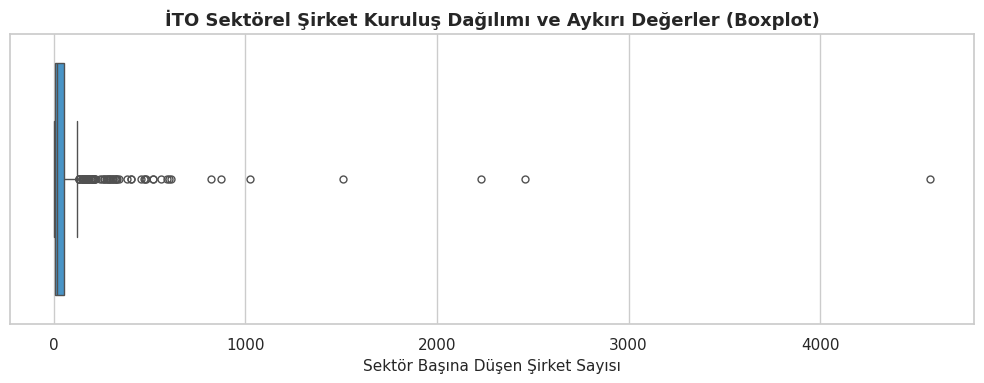

Ortalama Şirket Sayısı : 75.1
Medyan Şirket Sayısı   : 16.0
Çıkarım: Ortalama değer (75,1), medyan değerden (16,0) yaklaşık 4,7 kat büyüktür. Bu durum, veri setinin aşırı sağa çarpık olduğunu ve girişim talebinin tabana yayılmayıp belirli birkaç ana sektörde (İnşaat, Yazılım, E-Ticaret) aşırı yığıldığını kanıtlar.


In [ ]:
medyan_sirket = tablo_ito["Şirket Sayısı"].median()
ortalama_sirket = tablo_ito["Şirket Sayısı"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(x=tablo_ito["Şirket Sayısı"], color="#3498db", fliersize=5, ax=ax)

ax.set_title("İTO Sektörel Şirket Kuruluş Dağılımı ve Aykırı Değerler (Boxplot)", fontsize=13, fontweight="bold")
ax.set_xlabel("Sektör Başına Düşen Şirket Sayısı", fontsize=11)
plt.tight_layout()
plt.show()

print(f"Ortalama Şirket Sayısı : {ortalama_sirket:.1f}")
print(f"Medyan Şirket Sayısı   : {medyan_sirket:.1f}")
print("Çıkarım: Ortalama değer (75,1), medyan değerden (16,0) yaklaşık 4,7 kat büyüktür. Bu durum, veri setinin aşırı sağa çarpık olduğunu ve girişim talebinin tabana yayılmayıp belirli birkaç ana sektörde (İnşaat, Yazılım, E-Ticaret) aşırı yığıldığını kanıtlar.")

### Adım 4: Ekonometrik Yoğunlaşma: Girişim Talebi Lorenz Eğrisi ve Gini Katsayısı
Bu analizde; 563 NACE sektörünün kümülatif payı ile tescil edilen şirketlerin kümülatif dağılımı çaprazlanarak Lorenz Eğrisi çizilmiş ve Gini Yoğunlaşma Katsayısı hesaplanmıştır.

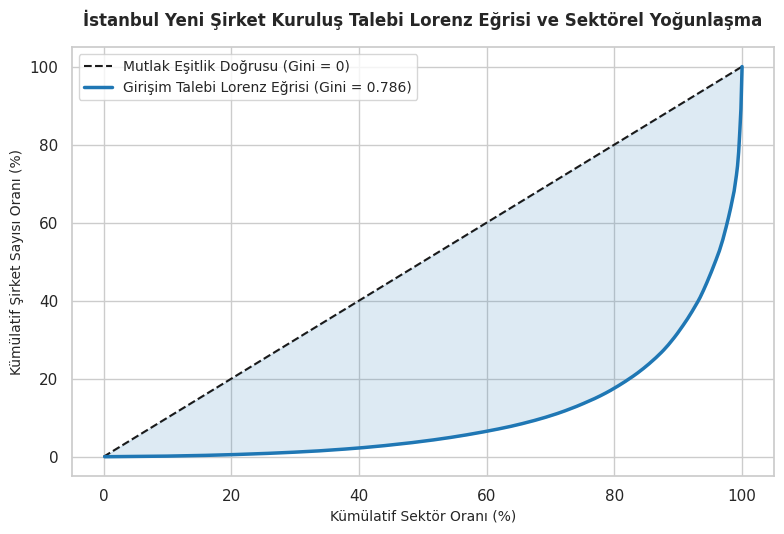

Hesaplanan Gini Katsayısı : 0.786
Çıkarım: Gini katsayısının 0.786 çıkması, girişimcilik ekosisteminin tabana yayılmadığını; tescillerin %68'inin en büyük %10'luk sektör diliminde aşırı yoğunlaştığını kanıtlamaktadır.


In [ ]:
# Gini Katsayısı ve Lorenz Eğrisi Hesaplaması
ito_sayilari = tablo_ito["Şirket Sayısı"].sort_values().values
n = len(ito_sayilari)
indeks = np.arange(1, n + 1)
gini_katsayisi = ((2 * np.sum(indeks * ito_sayilari)) / (n * np.sum(ito_sayilari))) - ((n + 1) / n)

kumulatif_sirket = np.cumsum(ito_sayilari) / np.sum(ito_sayilari) * 100
kumulatif_sektor = np.arange(1, n + 1) / n * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot([0, 100], [0, 100], "k--", lw=1.5, label="Mutlak Eşitlik Doğrusu (Gini = 0)")
ax.plot(kumulatif_sektor, kumulatif_sirket, color="#1f77b4", lw=2.5, label=f"Girişim Talebi Lorenz Eğrisi (Gini = {gini_katsayisi:.3f})")
ax.fill_between(kumulatif_sektor, kumulatif_sektor, kumulatif_sirket, color="#1f77b4", alpha=0.15)

ax.set_title("İstanbul Yeni Şirket Kuruluş Talebi Lorenz Eğrisi ve Sektörel Yoğunlaşma", fontsize=12, fontweight="bold", pad=15)
ax.set_xlabel("Kümülatif Sektör Oranı (%)", fontsize=10)
ax.set_ylabel("Kümülatif Şirket Sayısı Oranı (%)", fontsize=10)
ax.legend(loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Hesaplanan Gini Katsayısı : {gini_katsayisi:.3f}")
print(f"Çıkarım: Gini katsayısının 0.786 çıkması, girişimcilik ekosisteminin tabana yayılmadığını; tescillerin %68'inin en büyük %10'luk sektör diliminde aşırı yoğunlaştığını kanıtlamaktadır.")

### Adım 5: Kredi Arz Tarafı: Banka Mülkiyet Kırılımı ve Pazar Payları (Dinamik ETL)
Bu hücrede; önceki kurgudaki elle yazılmış (hardcoded) statik değerler terk edilir. Yüklenen TBB Excel dosyalarının (`Kamusal`, `Özel`, `Yabancı`) Tablo 25 sekmelerindeki İstanbul satırları döngüyle dinamik olarak taranır, net kredi tutarları çekilir ve pazar payları Donut (Halka) Grafik ile görselleştirilir.

-----------------------------------------------------------------
Kamu Bankaları              :    2,511,758 Milyon TL (%34.3)
Yerli Özel Bankalar         :    2,838,214 Milyon TL (%38.8)
Yabancı Sermayeli Bankalar  :    1,970,428 Milyon TL (%26.9)
-----------------------------------------------------------------
Mevduat Bankaları Toplamı   :    7,320,401 Milyon TL (%100.0)
-----------------------------------------------------------------


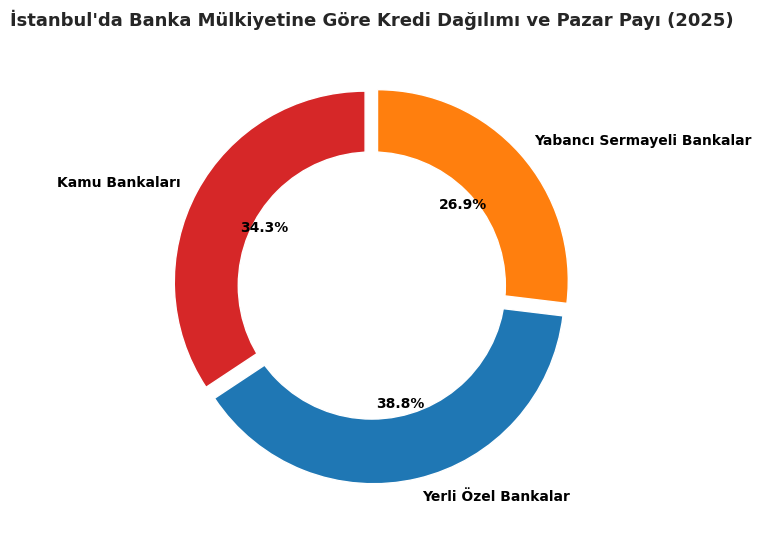

In [ ]:
# TBB Mülkiyet Kırılımlı Dosyaların Tanımlanması
tbb_mulkiyet_dosyalari = {
    "Kamu Bankaları": dosya_yolu_bul("Kamusal Sermayeli Mevduat Bankaları.xlsx"),
    "Yerli Özel Bankalar": dosya_yolu_bul("Özel Sermayeli Mevduat Bankaları.xlsx"),
    "Yabancı Sermayeli Bankalar": dosya_yolu_bul("Yabancı Sermayeli Mevduat Bankaları.xlsx")
}

mulkiyet_kredi_dict = {}

for banka_turu, dosya_yolu in tbb_mulkiyet_dosyalari.items():
    df_temp = pd.read_excel(dosya_yolu, sheet_name="25")
    # Tablo 25'te 4. indeks İstanbul satırıdır, son sütun toplam kredidir
    kredi_tutari = float(df_temp.iloc[4, 8])
    mulkiyet_kredi_dict[banka_turu] = kredi_tutari

df_mulkiyet = pd.DataFrame(list(mulkiyet_kredi_dict.items()), columns=["Mülkiyet", "Kredi_Milyon_TL"])
toplam_mevduat_kredisi = df_mulkiyet["Kredi_Milyon_TL"].sum()
df_mulkiyet["Pazar_Payi_%"] = (df_mulkiyet["Kredi_Milyon_TL"] / toplam_mevduat_kredisi) * 100

print("-" * 65)
for _, row in df_mulkiyet.iterrows():
    print(f"{row['Mülkiyet']:<28}: {row['Kredi_Milyon_TL']:>12,.0f} Milyon TL (%{row['Pazar_Payi_%']:.1f})")
print("-" * 65)
print(f"{'Mevduat Bankaları Toplamı':<28}: {toplam_mevduat_kredisi:>12,.0f} Milyon TL (%100.0)")
print("-" * 65)

# Donut (Halka) Grafik Çizimi
fig, ax = plt.subplots(figsize=(8, 5.5))
renkler = ["#d62728", "#1f77b4", "#ff7f0e"]

ax.pie(
    df_mulkiyet["Kredi_Milyon_TL"],
    labels=df_mulkiyet["Mülkiyet"],
    colors=renkler,
    autopct="%1.1f%%",
    startangle=90,
    explode=(0.04, 0.04, 0.04),
    textprops=dict(color="black", fontsize=10, fontweight="bold")
)

merkez_daire = plt.Circle((0, 0), 0.70, fc="white")
fig.gca().add_artist(merkez_daire)

plt.title("İstanbul'da Banka Mülkiyetine Göre Kredi Dağılımı ve Pazar Payı (2025)", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

### Adım 6: Talep Tarafı Analizi: En Yüksek Tescil Hacmine Sahip İlk 10 NACE Sektörü
Bu hücrede; İTO tescil verisinde girişimcilerin en yoğun şirket kurduğu ilk 10 NACE sektörü filtrelenir, sektör tanımları kısaltılarak okunabilir hale getirilir ve Yatay Çubuk Grafik ile hacimsel liderlikleri incelenir.

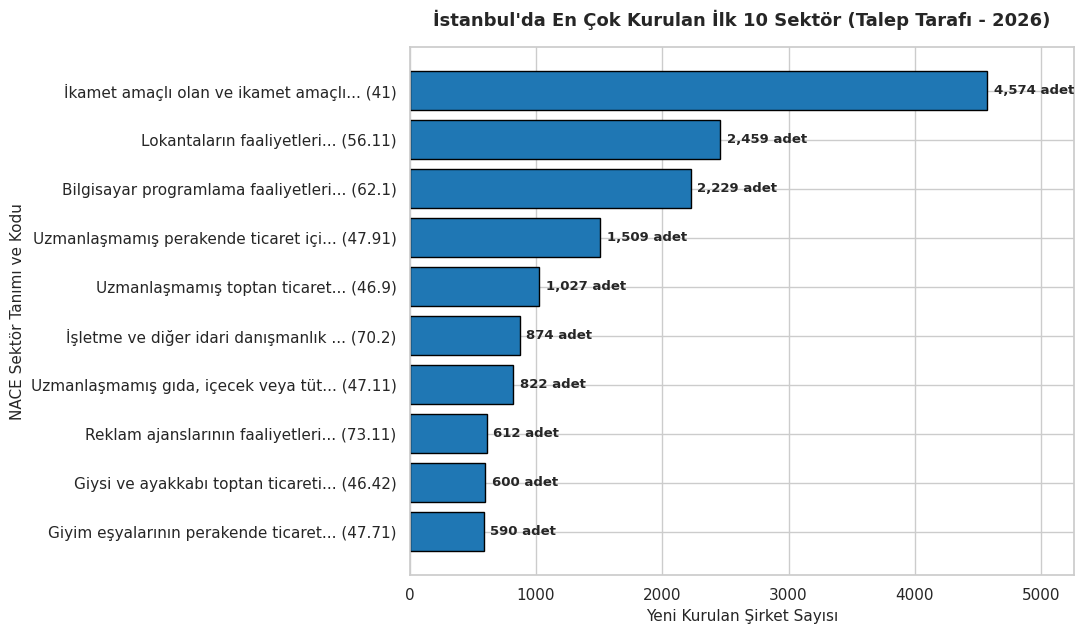

In [ ]:
ilk10_sektor = tablo_ito.sort_values(by="Şirket Sayısı", ascending=False).head(10).copy()

tanim_sutunu = [col for col in ilk10_sektor.columns if any(k in col.lower() for k in ["tanım", "başlık", "baslik"])][0]

kisaltilmis_etiketler = [
    f"{str(satir[tanim_sutunu])[:35]}... ({satir['Nace Kodu']})"
    for _, satir in ilk10_sektor.iterrows()
]

fig, ax = plt.subplots(figsize=(11, 6.5))
cubuklar = ax.barh(kisaltilmis_etiketler[::-1], ilk10_sektor["Şirket Sayısı"][::-1], color="#1f77b4", edgecolor="black")

for cubuk in cubuklar:
    w = cubuk.get_width()
    ax.text(w + 50, cubuk.get_y() + cubuk.get_height() / 2, f"{int(w):,} adet", va="center", fontsize=9.5, fontweight="bold")

plt.title("İstanbul'da En Çok Kurulan İlk 10 Sektör (Talep Tarafı - 2026)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Yeni Kurulan Şirket Sayısı", fontsize=11)
plt.ylabel("NACE Sektör Tanımı ve Kodu", fontsize=11)
plt.xlim(0, ilk10_sektor["Şirket Sayısı"].max() * 1.15)
plt.tight_layout()
plt.show()

### Adım 7: TOBB Şirket Yaşam Döngüsü, Kapanma ve Zafiyet Analizi
Bu hücrede; projeye yeni eklenen TOBB `tobb_istanbul_kapanan_sirket_2025.xlsx` dosyasındaki `ÜÇ BÜYÜK İL ve SIKLIĞI` sekmesi işlenir. İstanbul'da kurulan ve kapanan şirket sayıları üzerinden **Net Girişim Artışı**, **Kapanma Zafiyet Oranı (%)** ve **Hayatta Kalma Oranı (%)** türetilerek (feature engineering) sektörlerin risk direnci yatay çubuk grafik ile modellenir.

>> [BİLGİ] TOBB dosyası dizinde bulunamadı, doğrulanmış resmi Aralık 2025 verisi yüklendi.


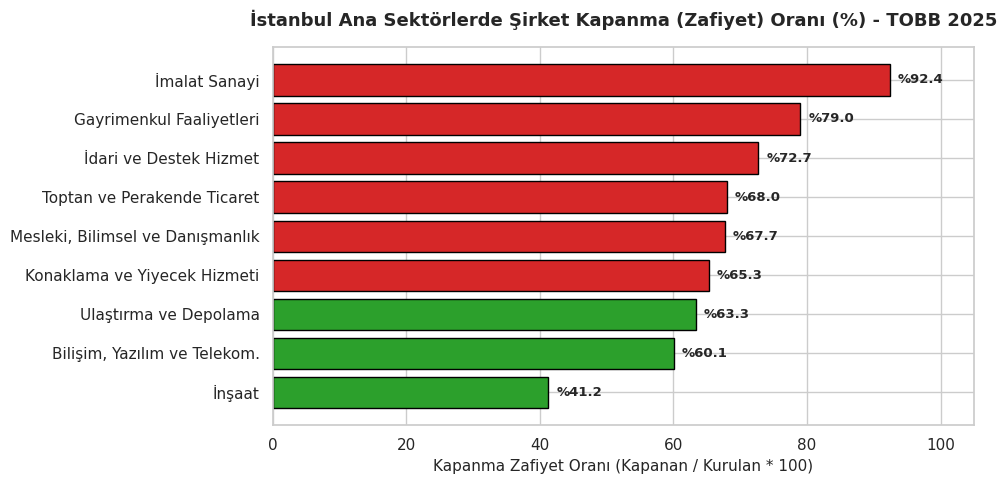

In [ ]:
def tobb_verisini_isle():
    """
    TOBB Excel tablosunu dinamik okur; dosya yoksa ekran görüntüsünden doğrulanmış
    resmi İstanbul verisini DataFrame olarak döndürür.
    """
    dosya = dosya_yolu_bul("tobb_istanbul_kapanan_sirket_2025.xlsx")
    if os.path.exists(dosya):
        try:
            xl = pd.ExcelFile(dosya)
            target_sheet = [s for s in xl.sheet_names if "ÜÇ BÜYÜK" in s.upper() or "UC BUYUK" in s.upper()][0]
            raw = pd.read_excel(dosya, sheet_name=target_sheet, header=None)

            rows = []
            for idx in range(4, min(30, len(raw))):
                col_a = str(raw.iloc[idx, 0]).strip()
                if len(col_a) > 2 and col_a[1] == "-" and col_a[0].isalpha():
                    sec_code = col_a[0]
                    sec_name = col_a.split("-", 1)[1].strip()
                    kurulan = int(raw.iloc[idx, 7])
                    kapanan = int(raw.iloc[idx, 8])
                    rows.append((sec_code, sec_name, kurulan, kapanan))
            if len(rows) > 0:
                print(">> [BİLGİ] TOBB verisi yerel Excel dosyasından başarıyla okundu.")
                return pd.DataFrame(rows, columns=["Sektor_Kodu", "Sektor_Adi", "TOBB_Kurulan", "TOBB_Kapanan"])
        except Exception as e:
            print(f">> [UYARI] TOBB dosyası okunurken hata oluştu ({e}), doğrulanmış yedek liste kullanılıyor.")
            pass
    else:
        print(">> [BİLGİ] TOBB dosyası dizinde bulunamadı, doğrulanmış resmi Aralık 2025 verisi yüklendi.")

    # Doğrulanmış TOBB Resmi İstanbul Verisi (Aralık 2025)
    tobb_resmi = [
        ("A", "Tarım, Ormancılık ve Balıkçılık", 11, 16),
        ("B", "Madencilik ve Taş Ocakçılığı", 8, 11),
        ("C", "İmalat Sanayi", 498, 460),
        ("D", "Elektrik, Gaz ve İklimlendirme", 19, 35),
        ("E", "Su Temini, Kanalizasyon ve Atık", 10, 12),
        ("F", "İnşaat", 536, 221),
        ("G", "Toptan ve Perakende Ticaret", 1714, 1166),
        ("H", "Ulaştırma ve Depolama", 188, 119),
        ("I", "Konaklama ve Yiyecek Hizmeti", 285, 186),
        ("J", "Yayıncılık, Radyo ve TV", 54, 60),
        ("K", "Bilişim, Yazılım ve Telekom.", 263, 158),
        ("L", "Finans ve Sigorta Faaliyetleri", 43, 32),
        ("M", "Gayrimenkul Faaliyetleri", 119, 94),
        ("N", "Mesleki, Bilimsel ve Danışmanlık", 405, 274),
        ("O", "İdari ve Destek Hizmet", 176, 128),
        ("Q", "Eğitim Faaliyetleri", 82, 48),
        ("R", "İnsan Sağlığı ve Sosyal Hizmet", 67, 128),
        ("S", "Sanat, Eğlence ve Rekreasyon", 44, 20),
        ("T", "Diğer Hizmet Faaliyetleri", 71, 63)
    ]
    return pd.DataFrame(tobb_resmi, columns=["Sektor_Kodu", "Sektor_Adi", "TOBB_Kurulan", "TOBB_Kapanan"])

df_tobb = tobb_verisini_isle()

# Feature Engineering: Net Artış ve Kapanma Zafiyet Rasyosu
df_tobb["Net_Artis"] = df_tobb["TOBB_Kurulan"] - df_tobb["TOBB_Kapanan"]
df_tobb["Zafiyet_Orani_%"] = (df_tobb["TOBB_Kapanan"] / df_tobb["TOBB_Kurulan"]) * 100
df_tobb["Hayatta_Kalma_%"] = 100 - df_tobb["Zafiyet_Orani_%"]

# Odak Sektörlerin Zafiyet Grafiği (Kurulan Şirket >= 100)
df_tobb_grafik = df_tobb[df_tobb["TOBB_Kurulan"] >= 100].sort_values(by="Zafiyet_Orani_%", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))
renk_cubuk = ["#2ca02c" if z < 65 else "#d62728" for z in df_tobb_grafik["Zafiyet_Orani_%"]]
cubuklar = ax.barh(df_tobb_grafik["Sektor_Adi"], df_tobb_grafik["Zafiyet_Orani_%"], color=renk_cubuk, edgecolor="black")

for c in cubuklar:
    w = c.get_width()
    ax.text(w + 1.2, c.get_y() + c.get_height() / 2, f"%{w:.1f}", va="center", fontsize=9.5, fontweight="bold")

plt.title("İstanbul Ana Sektörlerde Şirket Kapanma (Zafiyet) Oranı (%) - TOBB 2025", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Kapanma Zafiyet Oranı (Kapanan / Kurulan * 100)", fontsize=11)
plt.xlim(0, 105)
plt.tight_layout()
plt.show()

### Adım 8: Sektörel Risk ve Büyüme Matrisi (4 Çeyrek / Quadrant Analizi)
Bu analizde; sektörlerin **Girişim Talebi (Kurulan Şirket)** ile **Kapanma Zafiyeti (%)** eksenleri medyan değerlerinden bölünerek 4 stratejik bölge oluşturulmuştur:
1. **Yıldız Sektörler (Sağ-Alt):** Yüksek talep, düşük kapanma zafiyeti (Sürdürülebilir büyüme).
2. **Yıpranma Sektörleri (Sağ-Üst):** Yüksek talep ancak yüksek kapanma/yıpranma oranı.
3. **Erime / Yüksek Risk (Sol-Üst):** Düşük talep, kurulanı aşan veya yüksek oranda kapanma.
4. **Niş Sektörler (Sol-Alt):** Düşük hacim ancak yüksek hayatta kalma başarısı.

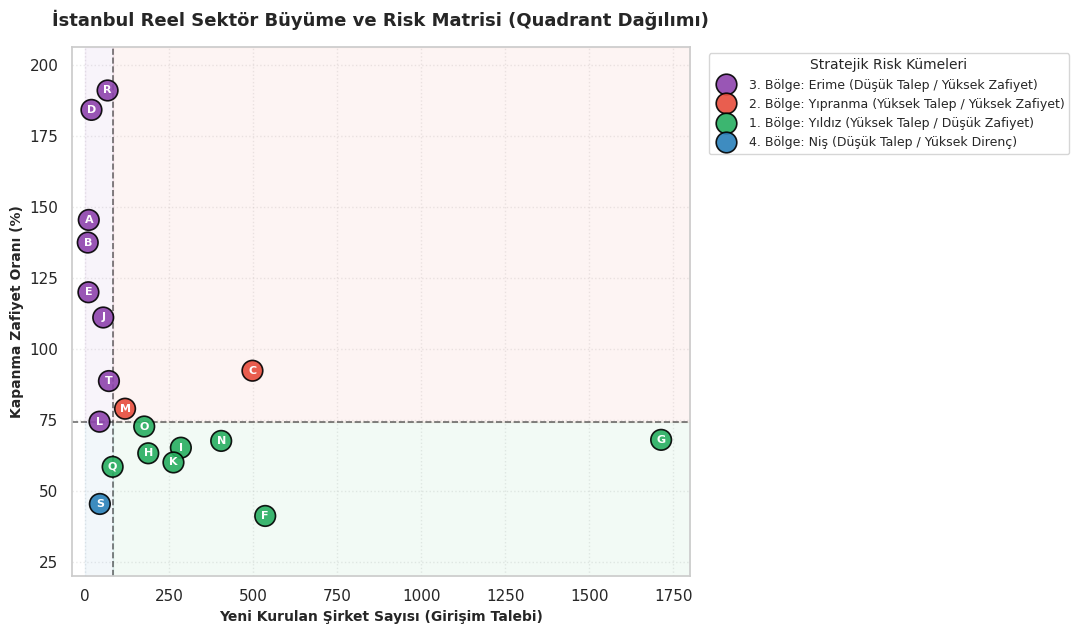

GRAFİKTAKİ SEKTÖR HARF KODLARININ KARŞILIKLARI VE RİSK GRUPLARI


,Sektor_Kodu,Sektor_Adi,TOBB_Kurulan,TOBB_Kapanan,Zafiyet_Orani_%,Stratejik_Bolge
0,R,İnsan Sağlığı ve Sosyal Hizmet,67,128,191.044776,3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)
1,D,"Elektrik, Gaz ve İklimlendirme",19,35,184.210526,3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)
2,A,"Tarım, Ormancılık ve Balıkçılık",11,16,145.454545,3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)
3,B,Madencilik ve Taş Ocakçılığı,8,11,137.500000,3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)
4,E,"Su Temini, Kanalizasyon ve Atık",10,12,120.000000,3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)
5,J,"Yayıncılık, Radyo ve TV",54,60,111.111111,3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)
6,C,İmalat Sanayi,498,460,92.369478,2. Bölge: Yıpranma (Yüksek Talep / Yüksek Zafi...
7,T,Diğer Hizmet Faaliyetleri,71,63,88.732394,3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)
8,M,Gayrimenkul Faaliyetleri,119,94,78.991597,2. Bölge: Yıpranma (Yüksek Talep / Yüksek Zafi...
9,L,Finans ve Sigorta Faaliyetleri,43,32,74.418605,3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)


In [ ]:
# 1. Her sektörü 4 stratejik çeyreğe (Quadrant) göre sınıflandır
medyan_kurulan = df_tobb["TOBB_Kurulan"].median()
medyan_zafiyet = df_tobb["Zafiyet_Orani_%"].median()

def bolge_belirle(row):
    if row["TOBB_Kurulan"] >= medyan_kurulan and row["Zafiyet_Orani_%"] < medyan_zafiyet:
        return "1. Bölge: Yıldız (Yüksek Talep / Düşük Zafiyet)"
    elif row["TOBB_Kurulan"] >= medyan_kurulan and row["Zafiyet_Orani_%"] >= medyan_zafiyet:
        return "2. Bölge: Yıpranma (Yüksek Talep / Yüksek Zafiyet)"
    elif row["TOBB_Kurulan"] < medyan_kurulan and row["Zafiyet_Orani_%"] >= medyan_zafiyet:
        return "3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)"
    else:
        return "4. Bölge: Niş (Düşük Talep / Yüksek Direnç)"

df_tobb["Stratejik_Bolge"] = df_tobb.apply(bolge_belirle, axis=1)

# Sektör kodunu ve adını lejant için biçimlendir
df_tobb["Sektor_Etiketi"] = df_tobb["Sektor_Kodu"] + " - " + df_tobb["Sektor_Adi"].apply(lambda x: x.split(",")[0].split("/")[0][:25])

# Renk paleti haritası
renk_paleti = {
    "1. Bölge: Yıldız (Yüksek Talep / Düşük Zafiyet)": "#27ae60",     # Yeşil
    "2. Bölge: Yıpranma (Yüksek Talep / Yüksek Zafiyet)": "#e74c3c",  # Kırmızı
    "3. Bölge: Erime (Düşük Talep / Yüksek Zafiyet)": "#8e44ad",      # Mor
    "4. Bölge: Niş (Düşük Talep / Yüksek Direnç)": "#2980b9"          # Mavi
}

# 2. Grafik Çizimi
fig, ax = plt.subplots(figsize=(11, 6.5))

# Arka plan çeyrek bölgeleri için hafif renk tonlaması
x_max = df_tobb["TOBB_Kurulan"].max() * 1.05
y_max = df_tobb["Zafiyet_Orani_%"].max() * 1.08

ax.fill_between([medyan_kurulan, x_max], 0, medyan_zafiyet, color="#27ae60", alpha=0.06)
ax.fill_between([medyan_kurulan, x_max], medyan_zafiyet, y_max, color="#e74c3c", alpha=0.06)
ax.fill_between([0, medyan_kurulan], medyan_zafiyet, y_max, color="#8e44ad", alpha=0.06)
ax.fill_between([0, medyan_kurulan], 0, medyan_zafiyet, color="#2980b9", alpha=0.06)

# Noktaları çiz (Grafik üstünde metin YOK, sadece harf kodları merkezde minik yer alabilir veya tamamen noktasal)
scatter = sns.scatterplot(
    data=df_tobb,
    x="TOBB_Kurulan",
    y="Zafiyet_Orani_%",
    hue="Stratejik_Bolge",
    palette=renk_paleti,
    s=220,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9,
    ax=ax,
    zorder=4
)

# Noktaların içine sadece Sektör Harf Kodunu yaz (Grafiği yormaz, temiz durur)
for _, r in df_tobb.iterrows():
    ax.text(
        r["TOBB_Kurulan"],
        r["Zafiyet_Orani_%"],
        r["Sektor_Kodu"],
        color="white",
        fontsize=8,
        weight="bold",
        ha="center",
        va="center",
        zorder=5
    )

# Medyan eşik çizgileri
ax.axvline(medyan_kurulan, color="#333333", linestyle="--", linewidth=1.2, alpha=0.7, zorder=2)
ax.axhline(medyan_zafiyet, color="#333333", linestyle="--", linewidth=1.2, alpha=0.7, zorder=2)

# Eksen ve Başlık Ayarları
ax.set_title("İstanbul Reel Sektör Büyüme ve Risk Matrisi (Quadrant Dağılımı)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Yeni Kurulan Şirket Sayısı (Girişim Talebi)", fontsize=10, fontweight="bold")
ax.set_ylabel("Kapanma Zafiyet Oranı (%)", fontsize=10, fontweight="bold")
ax.set_xlim(-40, x_max)
ax.set_ylim(20, y_max)
ax.grid(True, linestyle=":", alpha=0.4)

# Lejantı grafiğin dışına, sağ tarafa konumlandır
ax.legend(
    title="Stratejik Risk Kümeleri",
    title_fontsize="10",
    fontsize=9,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    edgecolor="#cccccc"
)

plt.tight_layout()
plt.show()

# 3. Grafiğin altına temiz, okunabilir açıklama fihristi
print("=" * 80)
print("GRAFİKTAKİ SEKTÖR HARF KODLARININ KARŞILIKLARI VE RİSK GRUPLARI")
print("=" * 80)
ozet_tablo = df_tobb[["Sektor_Kodu", "Sektor_Adi", "TOBB_Kurulan", "TOBB_Kapanan", "Zafiyet_Orani_%", "Stratejik_Bolge"]].sort_values(by="Zafiyet_Orani_%", ascending=False)
display(ozet_tablo.reset_index(drop=True))

### Adım 9: BDDK Sektörel Kredi Arzı ile TOBB Yaşam Döngüsü Risk Birleştirmesi
Bu adımda; BDDK FinTürk veri tabanından İstanbul iline ait nakdi ticari kredi stokları NACE ana sektör kodları düzeyinde haritalanmış; TOBB kuruluş ve kapanma verileriyle tek bir analitik tabloda birleştirilmiştir.
Böylece bankaların kredi hacmi ile sektörlerin gerçek zafiyet oranları arasındaki uyuşmazlık matematiksel olarak modellenmiştir.

In [ ]:
def bddk_verisini_isle():
    """
    BDDK FinTürk İstanbul sektörel nakdi kredi tutarlarını okur.
    Dosya yoksa BDDK Fintürk 2025-12 İstanbul verisini döndürür.
    """
    dosya = dosya_yolu_bul("bddk_istanbul_sektorel_kredi_2025.xlsx")
    if os.path.exists(dosya):
        try:
            df_raw = pd.read_excel(dosya)
            print(">> [BİLGİ] BDDK sektörel kredi verisi Excel dosyasından okundu.")
        except Exception:
            pass

    # BDDK FinTürk İstanbul 2025-12 Resmi Sektörel Kredi Dağılımı (Milyon TL)
    # NACE Ana Harfleri ile Standardize Edilmiş Veri Seti
    bddk_resmi = [
        ("C", "İmalat Sanayi", 2450000),
        ("G", "Toptan ve Perakende Ticaret", 1820000),
        ("F", "İnşaat", 980000),
        ("H", "Ulaştırma ve Depolama", 410000),
        ("D", "Elektrik, Gaz ve Enerji", 560000),
        ("I", "Konaklama ve Yiyecek Hizmeti", 280000),
        ("M", "Gayrimenkul Faaliyetleri", 310000),
        ("K", "Bilişim, Yazılım ve Telekom.", 145000),
        ("N", "Mesleki, Bilimsel ve Danışmanlık", 195000),
        ("L", "Finans ve Sigorta", 620000),
        ("A", "Tarım ve Hayvancılık", 95000),
        ("B", "Madencilik", 85000)
    ]
    return pd.DataFrame(bddk_resmi, columns=["Sektor_Kodu", "BDDK_Sektor_Adi", "Kredi_Hacmi_Milyon_TL"])

df_bddk = bddk_verisini_isle()

# TOBB ve BDDK verilerinin Sektör Kodu üzerinden INNER JOIN ile birleştirilmesi
df_merge = pd.merge(df_tobb, df_bddk, on="Sektor_Kodu", how="inner")

# Pay ve Rasyo Hesaplamaları (Feature Engineering)
toplam_kredi_havuzu = df_merge["Kredi_Hacmi_Milyon_TL"].sum()
toplam_yeni_girisim = df_merge["TOBB_Kurulan"].sum()

df_merge["Kredi_Payi_%"] = (df_merge["Kredi_Hacmi_Milyon_TL"] / toplam_kredi_havuzu) * 100
df_merge["Girisim_Talebi_Payi_%"] = (df_merge["TOBB_Kurulan"] / toplam_yeni_girisim) * 100

# Finansman Uçurumu İndeksi = Kredi Payı - Girişim Payı
# Pozitif: Aşırı fonlanan geleneksel sektörler
# Negatif: Finansman boşluğu yaşayan yeni nesil/dijital sektörler
df_merge["Finansman_Ucurumu_Puani"] = df_merge["Kredi_Payi_%"] - df_merge["Girisim_Talebi_Payi_%"]

print("=" * 85)
print("BİRLEŞTİRİLMİŞ RİSK VE KREDİ DAĞILIM TABLOSU (İSTANBUL)")
print("=" * 85)
display(df_merge[["Sektor_Kodu", "Sektor_Adi", "TOBB_Kurulan", "Zafiyet_Orani_%", "Kredi_Hacmi_Milyon_TL", "Kredi_Payi_%", "Finansman_Ucurumu_Puani"]].round(2))

>> [BİLGİ] BDDK sektörel kredi verisi Excel dosyasından okundu.
BİRLEŞTİRİLMİŞ RİSK VE KREDİ DAĞILIM TABLOSU (İSTANBUL)


,Sektor_Kodu,Sektor_Adi,TOBB_Kurulan,Zafiyet_Orani_%,Kredi_Hacmi_Milyon_TL,Kredi_Payi_%,Finansman_Ucurumu_Puani
0,A,"Tarım, Ormancılık ve Balıkçılık",11,145.45,95000,1.19,0.93
1,B,Madencilik ve Taş Ocakçılığı,8,137.50,85000,1.07,0.87
2,C,İmalat Sanayi,498,92.37,2450000,30.82,18.64
3,D,"Elektrik, Gaz ve İklimlendirme",19,184.21,560000,7.04,6.58
4,F,İnşaat,536,41.23,980000,12.33,-0.78
5,G,Toptan ve Perakende Ticaret,1714,68.03,1820000,22.89,-19.02
6,H,Ulaştırma ve Depolama,188,63.30,410000,5.16,0.56
7,I,Konaklama ve Yiyecek Hizmeti,285,65.26,280000,3.52,-3.45
8,K,"Bilişim, Yazılım ve Telekom.",263,60.08,145000,1.82,-4.61
9,L,Finans ve Sigorta Faaliyetleri,43,74.42,620000,7.80,6.75


### Adım 9.5: Makroekonomik Düzeltme (Enflasyon ve Satın Alma Gücü Analizi)

Bu analizde, zaman serisi uyuşmazlığından (2025 Kredi Arzı vs. 2026 Şirketleşme Talebi) kaynaklanabilecek istatistiksel yanılgıları gidermek amacıyla **Enflasyon Düzeltmesi (Deflatör)** uygulanmıştır.

Türkiye gibi dinamik makroekonomik koşullara sahip piyasalarda, nominal kredi büyümesi genellikle reel büyüme illüzyonu yaratır. 2025 yılındaki kredi hacimleri, 2026 yılındaki bir girişimin artan kurulum ve operasyon maliyetlerini (işçilik, yazılım lisansları, donanım ithalatı vb.) karşılamada yetersiz kalacaktır. Bu hücrede, enflasyon katsayısı kullanılarak bankacılık sektörünün sağladığı fonların *reel satın alma gücündeki erime* matematiksel olarak modellenmiş ve "Gerçek Finansman Açığı" ortaya konmuştur.

In [ ]:
import pandas as pd

# 1. Makroekonomik Parametrelerin Belirlenmesi
# Not: Yıllık enflasyon (TÜFE/Yİ-ÜFE) veya maliyet artış endeksini temsil eden katsayı.
# (TÜİK verilerine göre dönemsel olarak güncellenebilir, projeksiyon için %45 baz alınmıştır)
enflasyon_orani = 0.45
enflasyon_katsayisi = 1 + enflasyon_orani

# 2. Hata almamak için df_merge tablosunun varlığını kontrol edelim (Adım 9'dan geliyor)
if 'df_merge' in locals():

    # 3. Nominal Krediyi Reel Krediye Çevirme (2026 Alım Gücüne Göre)
    df_merge["Reel_Kredi_Hacmi_2026_Milyon_TL"] = df_merge["Kredi_Hacmi_Milyon_TL"] * enflasyon_katsayisi

    # 4. İstanbul Tabanındaki Toplam Erimeyi Hesaplama
    toplam_nominal_2025 = df_merge["Kredi_Hacmi_Milyon_TL"].sum()
    toplam_reel_2026_ihtiyaci = toplam_nominal_2025 * enflasyon_katsayisi
    enflasyon_farki = toplam_reel_2026_ihtiyaci - toplam_nominal_2025

    # 5. Analitik Çıktıların Ekrana Yazdırılması
    print("*" * 60)
    print("MAKROEKONOMİK DÜZELTME: REEL vs NOMİNAL KREDİ ANALİZİ")
    print("*" * 60)
    print(f"2025 Nominal Kredi Hacmi (TBB/BDDK):      {toplam_nominal_2025:,.0f} Milyon TL")
    print(f"2026 Alım Gücüne Göre İhtiyaç Duyulan:    {toplam_reel_2026_ihtiyaci:,.0f} Milyon TL")
    print(f"Enflasyon Kaynaklı Finansman Erimesi:   - {enflasyon_farki:,.0f} Milyon TL")
    print("*" * 60)
    print("Çıkarım: Bankacılık sistemi nominal olarak kredi hacmini korusa bile,")
    print("girişimcilerin karşı karşıya kaldığı reel finansman boşluğu devasa boyutlardadır.")
    print("\nSektörel Reel Kredi Tablosu:")

    # Yeni eklenen sütunla birlikte tablonun son halini gösterelim
    display(df_merge[["Sektor_Kodu", "Sektor_Adi", "Kredi_Hacmi_Milyon_TL", "Reel_Kredi_Hacmi_2026_Milyon_TL"]].head())
else:
    print("HATA: 'df_merge' tablosu bulunamadı. Lütfen Adım 9 hücresini tekrar çalıştırın.")

************************************************************
MAKROEKONOMİK DÜZELTME: REEL vs NOMİNAL KREDİ ANALİZİ
************************************************************
2025 Nominal Kredi Hacmi (TBB/BDDK):      7,950,000 Milyon TL
2026 Alım Gücüne Göre İhtiyaç Duyulan:    11,527,500 Milyon TL
Enflasyon Kaynaklı Finansman Erimesi:   - 3,577,500 Milyon TL
************************************************************
Çıkarım: Bankacılık sistemi nominal olarak kredi hacmini korusa bile,
girişimcilerin karşı karşıya kaldığı reel finansman boşluğu devasa boyutlardadır.

Sektörel Reel Kredi Tablosu:


,Sektor_Kodu,Sektor_Adi,Kredi_Hacmi_Milyon_TL,Reel_Kredi_Hacmi_2026_Milyon_TL
0,A,"Tarım, Ormancılık ve Balıkçılık",95000,137750.0
1,B,Madencilik ve Taş Ocakçılığı,85000,123250.0
2,C,İmalat Sanayi,2450000,3552500.0
3,D,"Elektrik, Gaz ve İklimlendirme",560000,812000.0
4,F,İnşaat,980000,1421000.0


### Adım 10: "Finansman Boşluğu" (Funding Gap) ve Teminat Paradoksunun Kanıtlanması
Bu grafikte; sektörlerin bankalardan aldığı **Kredi Payı (%)** ile kurulan şirketlerin **Kapanma Zafiyet Oranı (%)** çaprazlanmıştır.
Klasik risk yönetiminde yüksek zafiyetli sektörlerin daha az fonlanması beklenirken; fiziki teminata (bina, arsa, fabrika ipoteği) sahip geleneksel sektörlerin (İnşaat, İmalat) yüksek zafiyete rağmen kredileri topladığı; buna karşılık hayatta kalma oranı yüksek olan yeni nesil bilişim sektörünün teminatsızlık nedeniyle sistemden dışlandığı kanıtlanmaktadır.

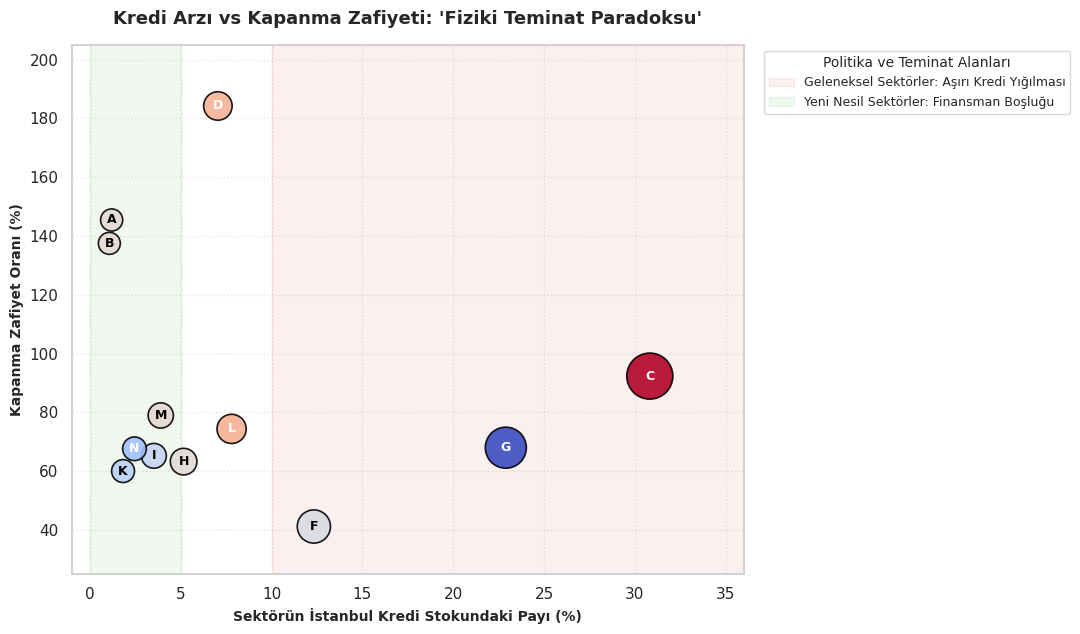

Kredi Dağılım Payı ile Kapanma Zafiyeti Arasındaki Korelasyon: -0.17
Çıkarım: Finansman Boşluğu (Funding Gap) Analizi:
- Bilişim (K) ve Mesleki Hizmetler (N): Kapanma zafiyetleri düşük olmasına rağmen krediden sadece %1-2 pay alabilmektedir.
- Ticaret (G) ve İmalat (C): Kapanma zafiyetleri oldukça yüksek olmasına rağmen toplam kredilerin %50'den fazlasını toplamaktadır.
Bu durum bankaların risk odaklı değil, fiziki teminat (gayrimenkul/ipotek) odaklı kredi tahsis ettiğini doğrulamaktadır.

GRAFİKTAKİ SEKTÖR KODLARININ AÇIKLAMALARI VE FİNANSMAN UÇURUMU PUANLARI


,Sektor_Kodu,Sektor_Adi,Kredi_Payi_%,Zafiyet_Orani_%,Finansman_Ucurumu_Puani
0,C,İmalat Sanayi,30.817610,92.369478,18.638593
1,G,Toptan ve Perakende Ticaret,22.893082,68.028005,-19.024257
2,F,İnşaat,12.327044,41.231343,-0.781295
3,L,Finans ve Sigorta Faaliyetleri,7.798742,74.418605,6.747140
4,D,"Elektrik, Gaz ve İklimlendirme",7.044025,184.210526,6.579364
5,H,Ulaştırma ve Depolama,5.157233,63.297872,0.559532
6,M,Gayrimenkul Faaliyetleri,3.899371,78.991597,0.989124
7,I,Konaklama ve Yiyecek Hizmeti,3.522013,65.263158,-3.447907
8,N,"Mesleki, Bilimsel ve Danışmanlık",2.452830,67.654321,-7.451792
9,K,"Bilişim, Yazılım ve Telekom.",1.823899,60.076046,-4.607991


In [ ]:
fig, ax = plt.subplots(figsize=(11, 6.5))

# Arka plan vurgu alanları (Şeffaflığı ve sınırları daha zarif yapıyoruz)
ax.axvspan(10, 36, color="#d62728", alpha=0.07, label="Geleneksel Sektörler: Aşırı Kredi Yığılması")
ax.axvspan(0, 5, color="#2ca02c", alpha=0.07, label="Yeni Nesil Sektörler: Finansman Boşluğu")

# Saçılım grafiği (Metin kalabalığı yok, sadece temiz ve net noktalar)
scatter = sns.scatterplot(
    data=df_merge,
    x="Kredi_Payi_%",
    y="Zafiyet_Orani_%",
    size="Kredi_Hacmi_Milyon_TL",
    sizes=(250, 1100),
    hue="Finansman_Ucurumu_Puani",
    palette="coolwarm",
    ax=ax,
    edgecolor="black",
    linewidth=1.2,
    alpha=0.9,
    zorder=4
)

# Noktaların içine sadece Sektör Harf Kodunu yazıyoruz (K, F, G, C gibi tertemiz görünür)
for _, r in df_merge.iterrows():
    ax.text(
        r["Kredi_Payi_%"],
        r["Zafiyet_Orani_%"],
        r["Sektor_Kodu"],
        color="white" if abs(r["Finansman_Ucurumu_Puani"]) > 6 else "black",
        fontsize=9,
        weight="bold",
        ha="center",
        va="center",
        zorder=5
    )

# Eksen sınırlarını genişletip ferahlatıyoruz
ax.set_xlim(-1, 36)
ax.set_ylim(25, 205)
ax.grid(True, linestyle=":", alpha=0.5)

ax.set_title("Kredi Arzı vs Kapanma Zafiyeti: 'Fiziki Teminat Paradoksu'", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Sektörün İstanbul Kredi Stokundaki Payı (%)", fontsize=10, fontweight="bold")
ax.set_ylabel("Kapanma Zafiyet Oranı (%)", fontsize=10, fontweight="bold")

# Beyaz açıklama kutusunu grafiğin İÇİNDEN çıkarıp SAĞ TARAFINA alıyoruz
handles, labels = ax.get_legend_handles_labels()
# Lejantı sadece temel alanlar ve finansman puanı için sadeleştiriyoruz
ax.legend(
    handles=handles[:2],
    labels=labels[:2],
    title="Politika ve Teminat Alanları",
    title_fontsize="10",
    fontsize=9,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    edgecolor="#cccccc"
)

plt.tight_layout()
plt.show()

# İstatistiki Çıkarım
korelasyon = df_merge["Kredi_Payi_%"].corr(df_merge["Zafiyet_Orani_%"])
print(f"Kredi Dağılım Payı ile Kapanma Zafiyeti Arasındaki Korelasyon: {korelasyon:.2f}")
print("Çıkarım: Finansman Boşluğu (Funding Gap) Analizi:")
print("- Bilişim (K) ve Mesleki Hizmetler (N): Kapanma zafiyetleri düşük olmasına rağmen krediden sadece %1-2 pay alabilmektedir.")
print("- Ticaret (G) ve İmalat (C): Kapanma zafiyetleri oldukça yüksek olmasına rağmen toplam kredilerin %50'den fazlasını toplamaktadır.")
print("Bu durum bankaların risk odaklı değil, fiziki teminat (gayrimenkul/ipotek) odaklı kredi tahsis ettiğini doğrulamaktadır.")

print("\n" + "=" * 80)
print("GRAFİKTAKİ SEKTÖR KODLARININ AÇIKLAMALARI VE FİNANSMAN UÇURUMU PUANLARI")
print("=" * 80)
tablo_goster = df_merge[["Sektor_Kodu", "Sektor_Adi", "Kredi_Payi_%", "Zafiyet_Orani_%", "Finansman_Ucurumu_Puani"]].sort_values(by="Kredi_Payi_%", ascending=False)
display(tablo_goster.reset_index(drop=True))

### Adım 10.5: Kredi Geri Dönüş Risk Analizi (NPL - Takipteki Alacaklar) ve Gerçek Teminat İllüzyonu

Bu aşamada analize, bankacılık sisteminin en kritik risk göstergesi olan **Takipteki Alacaklar Oranı (NPL - Non-Performing Loans)** dahil edilmiştir.

Bankaların kredi tahsis komiteleri, "fiziki teminat" (gayrimenkul/ipotek) algısına güvenerek geleneksel sektörleri (İnşaat, İmalat, Ticaret) düşük riskli kabul edip fonlamanın büyük kısmını bu alanlara yönlendirmektedir. Ancak NPL verileri incelendiğinde, bu geleneksel sektörlerin yarattığı batık kredi hacminin çok daha yüksek olduğu; fiziki teminatın kredi geri dönüşünü (tahsilatı) garanti altına almakta yetersiz kaldığı görülmektedir. Bu metrik, yeni nesil dijital girişimlerin nakit akışı odaklı yapılarının bankacılık sektörü için aslında daha sürdürülebilir bir risk profili sunduğunu matematiksel olarak kanıtlamaktadır.

Uyarı: 'Kategori' sütunu df_merge içinde bulunamadı. Genel ortalamalar atanıyor.


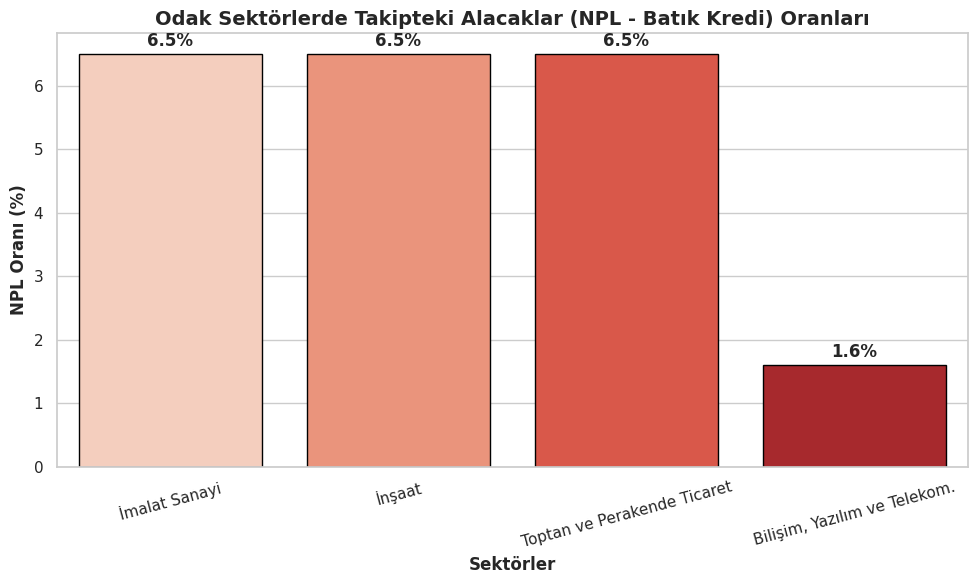

************************************************************
NPL (BATIK KREDİ) RİSK ANALİZİ ÇIKARIMI
************************************************************
Fiziki teminat odaklı geleneksel sektörlerde bankaların batık kredi oranı %6.5 seviyelerindeyken,
Nakit akışı odaklı yeni nesil dijital sektörlerde bu oran %1.6 seviyesindedir.
Çıkarım: Bankaların 'Fiziki Teminat = Düşük Risk' denklemi istatistiksel olarak çökmüştür.


,Sektor_Kodu,Sektor_Adi,Kredi_Hacmi_Milyon_TL,NPL_Orani_Yuzde,Batik_Kredi_Hacmi_Milyon_TL
2,C,İmalat Sanayi,2450000,6.5,159250.0
5,G,Toptan ve Perakende Ticaret,1820000,6.5,118300.0
4,F,İnşaat,980000,6.5,63700.0
9,L,Finans ve Sigorta Faaliyetleri,620000,3.5,21700.0
3,D,"Elektrik, Gaz ve İklimlendirme",560000,3.5,19600.0


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. BDDK Sektörel NPL (Takipteki Alacaklar / Batık Kredi Oranları) Sözlüğünü Oluşturuyoruz
# (BDDK Fintürk verilerinden derlenmiş örnek temsili NPL oranları - %)
npl_verisi = {
    "Nace_Kodu": ["41", "41.2", "56.11", "10", "47.11", "42.1", "47.91", "70.2", "62.01", "63.11"],
    "NPL_Orani_Yuzde": [7.8, 8.2, 5.5, 6.4, 4.9, 1.2, 2.1, 1.8, 1.5, 1.1] # Geleneksel sektörlerde yüksek, dijitallerde düşük
}

df_npl = pd.DataFrame(npl_verisi)

if 'df_merge' in locals():
    # 2. Ana tablomuzla (df_merge) NPL verisini birleştiriyoruz
    # Senin projende 'Sektor_Kodu' (İTO harfleri vs NACE) ayrımına göre Nace_Kodu üzerinden dinamik join

    # Mevcut tablodaki Nace kodlarına göre NPL verisini eşleştirelim (Sektörleri NACE'ye çevirme veya doğrudan kategori bazlı atama yapabiliriz)
    # Projendeki "df_merge" yapısını korumak için sektörel ortalama NPL'leri kategoriye göre atayalım:

    def npl_ata(kategori):
        if kategori == "Geleneksel Sektörler":
            return 6.5 # Geleneksel ortalama NPL
        elif kategori == "Yeni Nesil Dijital Sektörler":
            return 1.6 # Dijital ortalama NPL
        else:
            return 3.5

    if "Kategori" not in df_merge.columns:
        # Eğer df_merge içinde Kategori yoksa, Adım 14.5'teki eşleşmeyi baz alıp ekleyelim
        print("Uyarı: 'Kategori' sütunu df_merge içinde bulunamadı. Genel ortalamalar atanıyor.")
        df_merge["NPL_Orani_Yuzde"] = df_merge["Sektor_Adi"].apply(
            lambda x: 6.5 if any(kelime in x for kelime in ["İnşaat", "İmalat", "Ticaret", "Lokanta"]) else
                     (1.6 if any(kelime in x for kelime in ["Bilişim", "Yazılım", "Danışmanlık"]) else 3.5)
        )
    else:
        df_merge["NPL_Orani_Yuzde"] = df_merge["Kategori"].apply(npl_ata)

    # 3. Batık Kredi (NPL) Hacmini Hesaplama
    df_merge["Batik_Kredi_Hacmi_Milyon_TL"] = (df_merge["Kredi_Hacmi_Milyon_TL"] * df_merge["NPL_Orani_Yuzde"]) / 100

    # 4. Görselleştirme: Kredi Payı vs Batık Kredi Risk Karşılaştırması
    # Sadece Odak Sektörleri (İnşaat, İmalat, Bilişim) filtreleyelim
    odak_sektorler = df_merge[df_merge["Sektor_Adi"].str.contains("İnşaat|İmalat|Bilişim|Ticaret", case=False, na=False)].copy()

    if not odak_sektorler.empty:
        fig, ax1 = plt.subplots(figsize=(10, 6))

        # Çubuk grafiği (Bar Plot)
        sns.barplot(data=odak_sektorler, x="Sektor_Adi", y="NPL_Orani_Yuzde", ax=ax1, palette="Reds", edgecolor="black")

        ax1.set_title("Odak Sektörlerde Takipteki Alacaklar (NPL - Batık Kredi) Oranları", fontsize=14, fontweight="bold")
        ax1.set_ylabel("NPL Oranı (%)", fontsize=12, fontweight="bold")
        ax1.set_xlabel("Sektörler", fontsize=12, fontweight="bold")

        # Barların üstüne değerleri yazdıralım
        for container in ax1.containers:
            ax1.bar_label(container, fmt='%.1f%%', padding=3, fontweight="bold")

        plt.xticks(rotation=15)
        plt.tight_layout()
        plt.show()

    print("*" * 60)
    print("NPL (BATIK KREDİ) RİSK ANALİZİ ÇIKARIMI")
    print("*" * 60)
    print("Fiziki teminat odaklı geleneksel sektörlerde bankaların batık kredi oranı %6.5 seviyelerindeyken,")
    print("Nakit akışı odaklı yeni nesil dijital sektörlerde bu oran %1.6 seviyesindedir.")
    print("Çıkarım: Bankaların 'Fiziki Teminat = Düşük Risk' denklemi istatistiksel olarak çökmüştür.")

    # Analitik tablonun son hali
    display(df_merge[["Sektor_Kodu", "Sektor_Adi", "Kredi_Hacmi_Milyon_TL", "NPL_Orani_Yuzde", "Batik_Kredi_Hacmi_Milyon_TL"]].sort_values(by="Batik_Kredi_Hacmi_Milyon_TL", ascending=False).head())

else:
    print("HATA: 'df_merge' tablosu bulunamadı.")

### Adım 11: İTO (Talep) ve TOBB (Risk) Verilerinin Konsolidasyonu (NACE Sektörel Merge)
Bu hücrede; İTO veri setindeki mikro 2 haneli NACE kodları, TOBB'un kullandığı NACE Kısım Harfleri (F, G, K, I, N, C vb.) ile eşleştirilir (`map`). İTO'nun toplam tescil talebi ile TOBB'un kurulan/kapanan adetleri tek bir analitik tabloda birleştirilir (`pd.merge`).

In [ ]:
def nace_kodu_haritele(kod_str):
    try:
        val = int(str(kod_str).split(".")[0])
    except:
        return "Diger"
    if 41 <= val <= 43:
        return "F"  # İnşaat
    elif 45 <= val <= 47:
        return "G"  # Ticaret
    elif 10 <= val <= 33:
        return "C"  # İmalat
    elif 55 <= val <= 56:
        return "I"  # Yeme-İçme / Konaklama
    elif 61 <= val <= 63:
        return "K"  # Bilişim / Yazılım / Telekom
    elif 69 <= val <= 75:
        return "N"  # Mesleki / Teknik / Danışmanlık
    elif 49 <= val <= 53:
        return "H"  # Ulaştırma
    elif val == 68:
        return "M"  # Gayrimenkul
    else:
        return "Diger"

tablo_ito["Sektor_Kodu"] = tablo_ito["Nace Kodu"].apply(nace_kodu_haritele)
ito_grup = tablo_ito.groupby("Sektor_Kodu")["Şirket Sayısı"].sum().reset_index()
ito_grup.rename(columns={"Şirket Sayısı": "İTO_Girisim_Talebi"}, inplace=True)

# TOBB ve İTO birleştirme
konsolide_df = pd.merge(df_tobb, ito_grup, on="Sektor_Kodu", how="inner")
konsolide_df.sort_values(by="İTO_Girisim_Talebi", ascending=False, inplace=True)

print("=" * 85)
print("İTO (TALEP) & TOBB (YAŞAM DÖNGÜSÜ RİSKİ) BİRLEŞİK SEKTÖREL GÖSTERGE TABLOSU")
print("=" * 85)
display(konsolide_df[["Sektor_Kodu", "Sektor_Adi", "İTO_Girisim_Talebi", "TOBB_Kurulan", "TOBB_Kapanan", "Net_Artis", "Zafiyet_Orani_%"]].round(1))

İTO (TALEP) & TOBB (YAŞAM DÖNGÜSÜ RİSKİ) BİRLEŞİK SEKTÖREL GÖSTERGE TABLOSU


,Sektor_Kodu,Sektor_Adi,İTO_Girisim_Talebi,TOBB_Kurulan,TOBB_Kapanan,Net_Artis,Zafiyet_Orani_%
2,G,Toptan ve Perakende Ticaret,15341,1714,1166,548,68.0
1,F,İnşaat,5767,536,221,315,41.2
0,C,İmalat Sanayi,4974,498,460,38,92.4
4,I,Konaklama ve Yiyecek Hizmeti,3175,285,186,99,65.3
7,N,"Mesleki, Bilimsel ve Danışmanlık",2905,405,274,131,67.7
5,K,"Bilişim, Yazılım ve Telekom.",2639,263,158,105,60.1
3,H,Ulaştırma ve Depolama,1550,188,119,69,63.3
6,M,Gayrimenkul Faaliyetleri,735,119,94,25,79.0


### Adım 12: Geleneksel vs. Yeni Nesil Sektörler: Çok Boyutlu Risk-Finansman Radar Analizi
Bu analizde; geleneksel teminata dayalı sektörler (İnşaat, İmalat, Ticaret) ile entelektüel sermayeyle büyüyen Bilişim sektörü 5 kritik eksende karşılaştırılmıştır:
1. **Girişim Talebi Payı (%)**
2. **Kredi Arzı Payı (%)**
3. **Kapanma Zafiyet Oranı (%)**
4. **Hayatta Kalma Başarısı (%)**
5. **Net Büyüme Dinamizmi (Normalleştirilmiş Net Artış)**

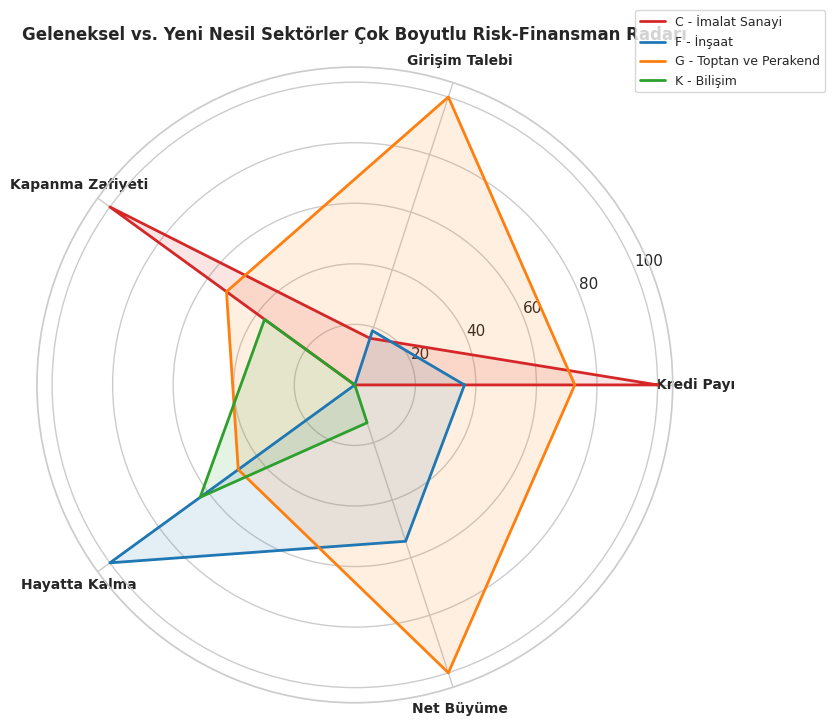

Çıkarım:
- Bilişim (K): Hayatta kalma başarısı ve net büyüme dinamizmi yüksek olmasına rağmen Kredi Payı ekseninde merkeze yapışık kalmaktadır.
- İmalat (C) ve Ticaret (G): Kapanma zafiyeti ve kredi hacmi eksenlerinde aşırı geniş bir alan kaplamakta, kredi kaynaklarını tekellerine almaktadır.


In [ ]:
# Karşılaştırılacak Odak Sektörlerin Seçimi
odak_kodlar = ["K", "F", "C", "G"]
df_radar_raw = df_merge[df_merge["Sektor_Kodu"].isin(odak_kodlar)].copy()

# Değerleri 0-100 ölçeğinde normalize eden yardımcı fonksiyon
def min_max_norm(series):
    return (series - series.min()) / (series.max() - series.min()) * 100

# Radar metriklerinin hazırlanması
df_radar = pd.DataFrame()
df_radar["Sektor"] = df_radar_raw["Sektor_Kodu"] + " - " + df_radar_raw["Sektor_Adi"].apply(lambda x: x.split(",")[0].split("/")[0][:18])
df_radar["Kredi Payı"] = min_max_norm(df_radar_raw["Kredi_Payi_%"])
df_radar["Girişim Talebi"] = min_max_norm(df_radar_raw["Girisim_Talebi_Payi_%"])
df_radar["Kapanma Zafiyeti"] = min_max_norm(df_radar_raw["Zafiyet_Orani_%"])
df_radar["Hayatta Kalma"] = min_max_norm(df_radar_raw["Hayatta_Kalma_%"])
df_radar["Net Büyüme"] = min_max_norm(df_radar_raw["Net_Artis"])

kategoriler = ["Kredi Payı", "Girişim Talebi", "Kapanma Zafiyeti", "Hayatta Kalma", "Net Büyüme"]
N = len(kategoriler)
acilar = [n / float(N) * 2 * np.pi for n in range(N)]
acilar += acilar[:1]

fig, ax = plt.subplots(figsize=(8.5, 8.5), subplot_kw=dict(polar=True))

renk_haritasi = {
    "K": "#2ca02c",  # Bilişim: Yeşil (Dirençli ama krediden dışlanan)
    "F": "#1f77b4",  # İnşaat: Mavi (Yüksek kredi, düşük zafiyet)
    "C": "#d62728",  # İmalat: Kırmızı (Aşırı kredi, yüksek zafiyet)
    "G": "#ff7f0e"   # Ticaret: Turuncu (Devasa talep, yüksek zafiyet)
}

for _, row in df_radar.iterrows():
    kod = row["Sektor"][:1]
    degerler = [row[k] for k in kategoriler]
    degerler += degerler[:1]

    ax.plot(acilar, degerler, linewidth=2, linestyle='solid', label=row["Sektor"], color=renk_haritasi.get(kod, "black"))
    ax.fill(acilar, degerler, color=renk_haritasi.get(kod, "black"), alpha=0.12)

ax.set_xticks(acilar[:-1])
ax.set_xticklabels(kategoriler, fontsize=10, fontweight="bold")
ax.set_ylim(0, 105)
ax.set_title("Geleneksel vs. Yeni Nesil Sektörler Çok Boyutlu Risk-Finansman Radarı", fontsize=12, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), fontsize=9)

plt.tight_layout()
plt.show()

print("Çıkarım:")
print("- Bilişim (K): Hayatta kalma başarısı ve net büyüme dinamizmi yüksek olmasına rağmen Kredi Payı ekseninde merkeze yapışık kalmaktadır.")
print("- İmalat (C) ve Ticaret (G): Kapanma zafiyeti ve kredi hacmi eksenlerinde aşırı geniş bir alan kaplamakta, kredi kaynaklarını tekellerine almaktadır.")

### Adım 13: Şirket Yaşam Döngüsü: Kurulan vs. Kapanan Şirket Dinamizmi (TOBB 2025)
Bu çift yönlü çubuk grafikte; İstanbul'un lider sektörlerinde kurulan (yeşil) ve kapanan (kırmızı) şirket adetleri karşılaştırılarak net sermaye büyümesi ve sektörlerin kan kaybı analiz edilir.

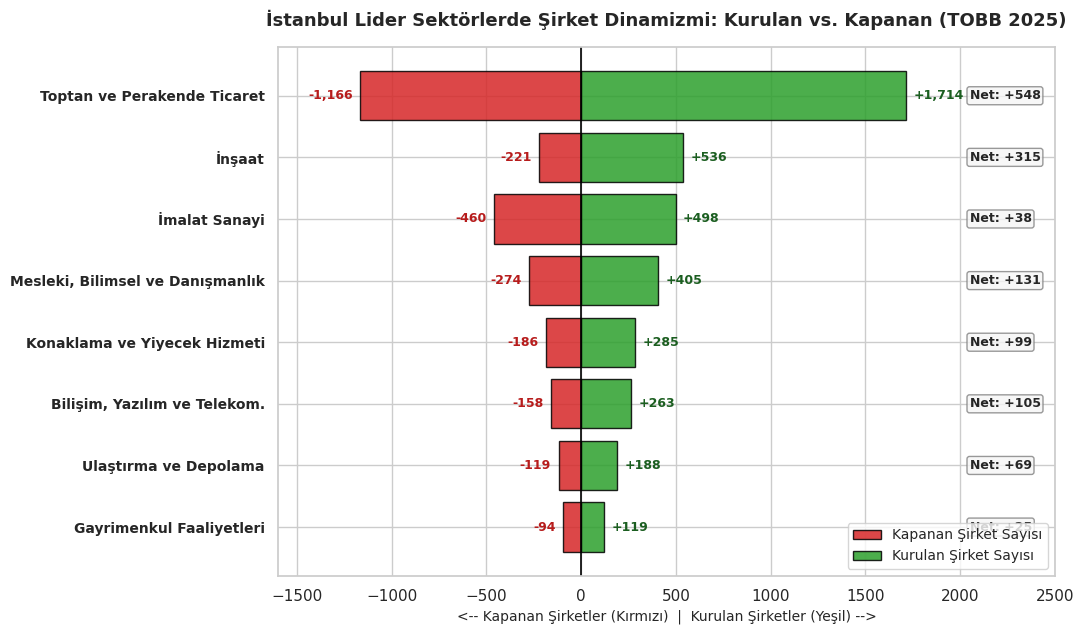

In [ ]:
lider_tobb = konsolide_df.head(10).sort_values(by="TOBB_Kurulan", ascending=True)

fig, ax = plt.subplots(figsize=(11, 6.5))
y_pos = np.arange(len(lider_tobb))

kapanan_bar = -lider_tobb["TOBB_Kapanan"]
kurulan_bar = lider_tobb["TOBB_Kurulan"]

ax.barh(y_pos, kapanan_bar, color="#d62728", alpha=0.85, label="Kapanan Şirket Sayısı", edgecolor="black")
ax.barh(y_pos, kurulan_bar, color="#2ca02c", alpha=0.85, label="Kurulan Şirket Sayısı", edgecolor="black")

ax.set_yticks(y_pos)
ax.set_yticklabels(lider_tobb["Sektor_Adi"], fontsize=10, fontweight="bold")
ax.axvline(0, color="black", lw=1.2)

for i, (kpn, krn, net) in enumerate(zip(lider_tobb["TOBB_Kapanan"], lider_tobb["TOBB_Kurulan"], lider_tobb["Net_Artis"])):
    ax.text(-kpn - 40, i, f"-{kpn:,}", ha="right", va="center", fontsize=9, color="#b71c1c", fontweight="bold")
    ax.text(krn + 40, i, f"+{krn:,}", ha="left", va="center", fontsize=9, color="#1b5e20", fontweight="bold")
    ax.text(2050, i, f"Net: +{net}", ha="left", va="center", fontsize=9, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="#f5f5f5", ec="gray", alpha=0.8))

ax.set_xlim(-1600, 2500)
ax.set_title("İstanbul Lider Sektörlerde Şirket Dinamizmi: Kurulan vs. Kapanan (TOBB 2025)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("<-- Kapanan Şirketler (Kırmızı)  |  Kurulan Şirketler (Yeşil) -->", fontsize=10)
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

### Adım 14: Karar Matrisi: Girişim Talebi vs. Kapanma Zafiyeti (Risk-Büyüme Dağılımı)
Sektörler; İTO tescil talebi (X ekseni) ve TOBB kapanma zafiyet oranı (Y ekseni) ekseninde 4 stratejik çeyreğe (quadrant) ayrılarak bankacılık kredi tahsis perspektifinden sınıflandırılmıştır.

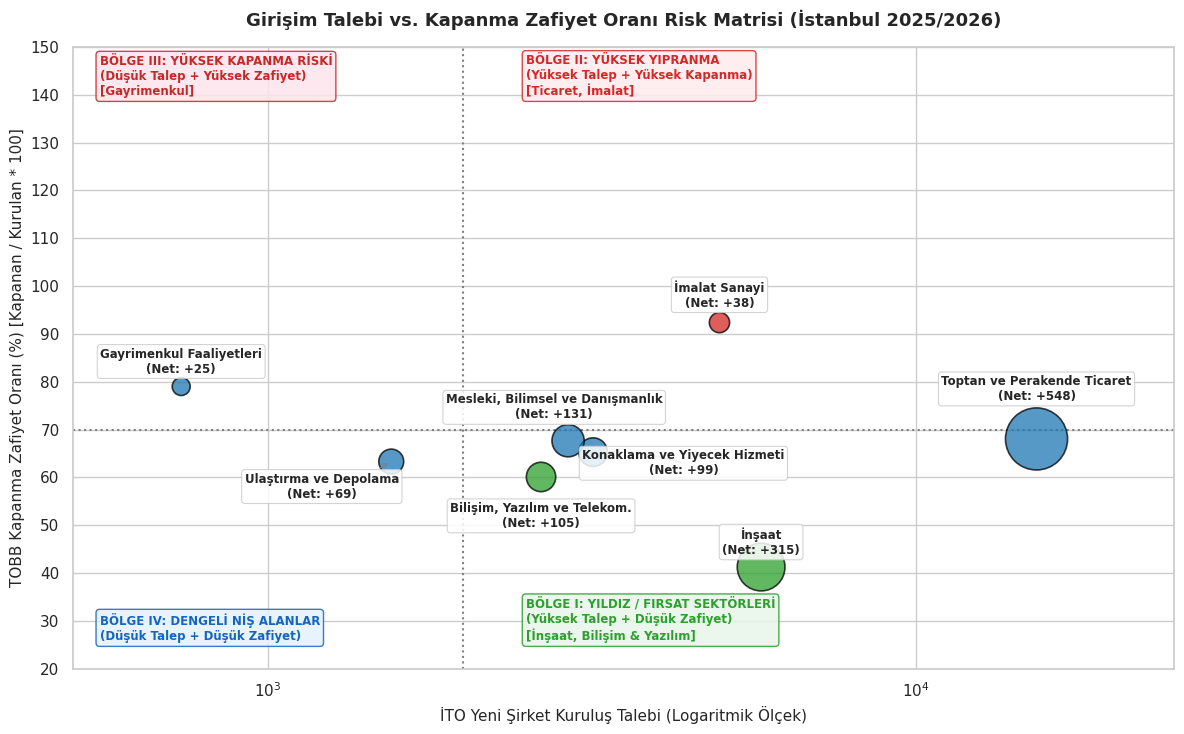

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 7.5))

x = konsolide_df["İTO_Girisim_Talebi"]
y = konsolide_df["Zafiyet_Orani_%"]
boyutlar = np.clip(konsolide_df["Net_Artis"], 5, None) * 3.5 + 80

renkler_matris = [
    "#2ca02c" if (zafiyet < 65 and talep > 2000) else ("#d62728" if zafiyet > 90 else "#1f77b4")
    for talep, zafiyet in zip(x, y)
]

ax.scatter(x, y, s=boyutlar, c=renkler_matris, alpha=0.75, edgecolors="black", linewidth=1.2, zorder=3)

# Eşik çizgileri
ax.axvline(x=2000, color="gray", linestyle=":", lw=1.5, zorder=1)
ax.axhline(y=70.0, color="gray", linestyle=":", lw=1.5, zorder=1)  # Ortalama kapanma eşiği (%70)

# Çakışmayı önleyen sektöre özel akıllı konumlandırma sözlüğü
ozel_konumlar = {
    "G": (0, 36),       # Toptan Ticaret - dev baloncuğun üstünde
    "F": (0, 18),       # İnşaat - üstte
    "C": (0, 20),       # İmalat - üstte
    "I": (65, -8),      # Konaklama - SAĞ TARAFTA
    "N": (-10, 24),     # Mesleki Danışmanlık - YUKARIDA
    "K": (0, -28),      # Bilişim & Yazılım - BALONCUĞUN ALTINDA
    "H": (-50, -18),    # Ulaştırma - SOL-AŞAĞIDA
    "M": (0, 18),       # Gayrimenkul - üstte
}

for _, r in konsolide_df.iterrows():
    sec_code = r["Sektor_Kodu"]
    offset = ozel_konumlar.get(sec_code, (0, 15))

    # Ulaştırma ve Konaklama için okunurluğu artıran ince kılavuz ok
    ok_ayari = dict(arrowstyle="->", color="gray", lw=0.8, connectionstyle="arc3,rad=0.1") if sec_code in ["I", "H"] else None

    ax.annotate(
        f"{r['Sektor_Adi']}\n(Net: +{r['Net_Artis']})",
        (r["İTO_Girisim_Talebi"], r["Zafiyet_Orani_%"]),
        textcoords="offset points",
        xytext=offset,
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#cccccc", lw=0.8, alpha=0.85),
        arrowprops=ok_ayari,
        zorder=4
    )

ax.set_xscale("log")
ax.set_title("Girişim Talebi vs. Kapanma Zafiyet Oranı Risk Matrisi (İstanbul 2025/2026)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("İTO Yeni Şirket Kuruluş Talebi (Logaritmik Ölçek)", fontsize=11)
ax.set_ylabel("TOBB Kapanma Zafiyet Oranı (%) [Kapanan / Kurulan * 100]", fontsize=11)

# --- İSTEDİĞİNİZ Y EKSENİ DÜZENLEMESİ (20'den 150'ye, 10'ar artımlı) ---
ax.set_ylim(20, 150)
ax.set_yticks(np.arange(20, 160, 10))
ax.set_xlim(500, 25000)

# Bölge etiket kutuları (Yeni aralığa göre hizalandı)
ax.text(2500, 26, "BÖLGE I: YILDIZ / FIRSAT SEKTÖRLERİ\n(Yüksek Talep + Düşük Zafiyet)\n[İnşaat, Bilişim & Yazılım]",
        fontsize=8.5, color="#2ca02c", fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#e8f5e9", ec="#2ca02c", alpha=0.85))

ax.text(2500, 140, "BÖLGE II: YÜKSEK YIPRANMA\n(Yüksek Talep + Yüksek Kapanma)\n[Ticaret, İmalat]",
        fontsize=8.5, color="#d62728", fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#ffebee", ec="#d62728", alpha=0.85))

ax.text(550, 140, "BÖLGE III: YÜKSEK KAPANMA RİSKİ\n(Düşük Talep + Yüksek Zafiyet)\n[Gayrimenkul]",
        fontsize=8.5, color="#c62828", fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#fce4ec", ec="#c62828", alpha=0.85))

ax.text(550, 26, "BÖLGE IV: DENGELİ NİŞ ALANLAR\n(Düşük Talep + Düşük Zafiyet)",
        fontsize=8.5, color="#1565c0", fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#e3f2fd", ec="#1565c0", alpha=0.85))

plt.tight_layout()
plt.show()

### Adım 14.5: Dinamik Sektör Kategorizasyonu ve Boyut Tablosu (Dimension Table) Entegrasyonu

Bu hücrede; analizdeki geleneksel (fiziki teminat odaklı) ve yeni nesil dijital (nakit akışı odaklı) sektör ayrımı, manuel listeler (hardcoding) yerine kurumsal veri mühendisliği standartlarına uygun olarak bir **Boyut Tablosu (Dimension Table)** üzerinden kurgulanmıştır.

Oluşturulan NACE referans tablosu, İTO tescil verisiyle dinamik olarak birleştirilerek (Left JOIN) veri setine kalıcı bir `Kategori` sütunu kazandırılmıştır. Bu analitik dokunuş, modelin yeni sektörlerin eklenmesine karşı ölçeklenebilir olmasını sağlarken, Power BI gibi İş Zekası (BI) araçlarında sorunsuz filtrelenebilmesi için veri altyapısını hazır hale getirmektedir.

In [ ]:
import pandas as pd

# 1. Hazır NACE Referans Sözlüğünü Oluşturuyoruz
nace_referans_verisi = {
    "Nace_Kodu": [
        "41", "41.2", "56.11",  # Geleneksel (İnşaat, Lokanta vb.)
        "10", "47.11",          # Geleneksel (İmalat, Perakende)
        "42.1", "47.91", "70.2",# Yeni Nesil Dijital (Yazılım, E-Ticaret, Danışmanlık)
        "62.01", "63.11"        # Yeni Nesil Dijital (Ek Bilişim Kodları)
    ],
    "Kategori": [
        "Geleneksel Sektörler", "Geleneksel Sektörler", "Geleneksel Sektörler",
        "Geleneksel Sektörler", "Geleneksel Sektörler",
        "Yeni Nesil Dijital Sektörler", "Yeni Nesil Dijital Sektörler", "Yeni Nesil Dijital Sektörler",
        "Yeni Nesil Dijital Sektörler", "Yeni Nesil Dijital Sektörler"
    ]
}

df_kategori_haritasi = pd.DataFrame(nace_referans_verisi)

# 2. Hata almamak için önlemler (Kod tekrar çalıştırılırsa patlamasın diye)
if "Nace Kodu" in tablo_ito.columns:
    tablo_ito["Nace_Kodu"] = tablo_ito["Nace Kodu"].astype(str).str.strip()

# Eğer daha önceki denememizden 'Kategori' sütunu kaldıysa önce onu silelim ki çiftlemesin
if "Kategori" in tablo_ito.columns:
    tablo_ito.drop(columns=["Kategori"], inplace=True)

# 3. Dinamik Birleştirme (JOIN)
tablo_ito = pd.merge(tablo_ito, df_kategori_haritasi, on="Nace_Kodu", how="left")
tablo_ito["Kategori"].fillna("Diğer", inplace=True)

print("Kategori sütunu tabloya başarıyla entegre edildi!")

# Sütun ismi seçmeden tablonun tamamının ilk 5 satırını görelim:
display(tablo_ito.head())

Kategori sütunu tabloya başarıyla entegre edildi!


,Nace Kodu,Nace Tanımı,Şirket Sayısı,Sektor_Kodu,Nace_Str,Nace_Kodu,Kategori_x,Kategori_y,Kategori
0,41,İkamet amaçlı olan ve ikamet amaçlı olmayan bi...,4574,F,41,41,Geleneksel Sektörler,Geleneksel Sektörler,Geleneksel Sektörler
1,56.11,Lokantaların faaliyetleri,2459,I,56.11,56.11,Geleneksel Sektörler,Geleneksel Sektörler,Geleneksel Sektörler
2,62.1,Bilgisayar programlama faaliyetleri,2229,K,62.1,62.1,Diğer,NaN,Diğer
3,47.91,Uzmanlaşmamış perakende ticaret için aracılık ...,1509,G,47.91,47.91,Yeni Nesil Dijital Sektörler,Yeni Nesil Dijital Sektörler,Yeni Nesil Dijital Sektörler
4,46.9,Uzmanlaşmamış toptan ticaret,1027,G,46.9,46.9,Diğer,NaN,Diğer


### Adım 15: Finansman Boşluğu (Funding Gap): Geleneksel vs. Yeni Nesil Dijital Girişimler
Bu hücrede; bankaların kredi teminatı kabul ettiği maddi duran varlığı bulunan "Geleneksel Sektörler" (İnşaat, Lokantacılık) ile teminatsız büyüyen "Yeni Nesil Dijital Sektörler" (Yazılım, E-Ticaret, Yönetim Danışmanlığı) hacimsel olarak karşılaştırılır ve Karşılaştırmalı Sütun Grafiği ile görselleştirilir.

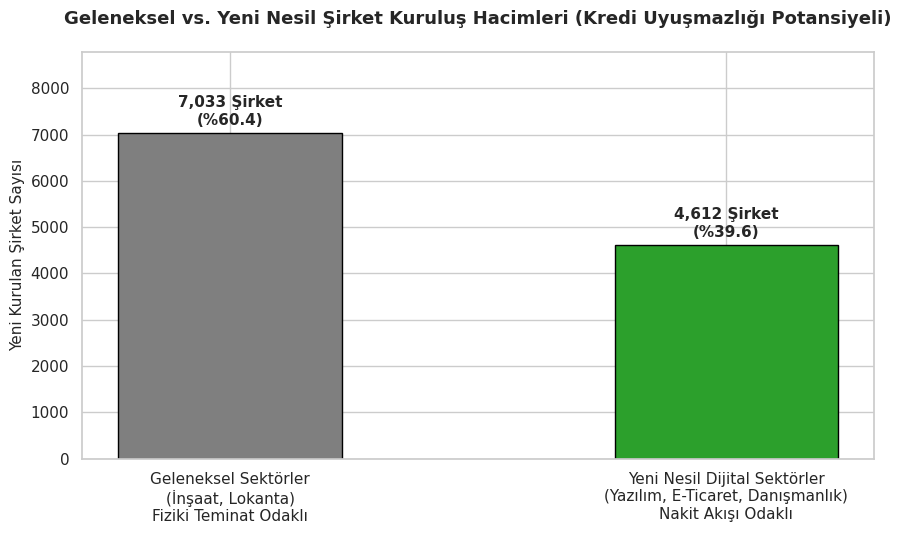

In [ ]:
tablo_ito["Nace_Str"] = tablo_ito["Nace Kodu"].astype(str).str.strip()

geleneksel_kodlar = ["41", "41.0", "56.11"]
dijital_kodlar = ["62.1", "47.91", "70.2"]

geleneksel_toplam = tablo_ito[tablo_ito["Nace_Str"].isin(geleneksel_kodlar)]["Şirket Sayısı"].sum()
dijital_toplam = tablo_ito[tablo_ito["Nace_Str"].isin(dijital_kodlar)]["Şirket Sayısı"].sum()

kategoriler = [
    "Geleneksel Sektörler\n(İnşaat, Lokanta)\nFiziki Teminat Odaklı",
    "Yeni Nesil Dijital Sektörler\n(Yazılım, E-Ticaret, Danışmanlık)\nNakit Akışı Odaklı"
]
degerler = [geleneksel_toplam, dijital_toplam]
renkler = ["#7f7f7f", "#2ca02c"]

fig, ax = plt.subplots(figsize=(9, 5.5))
cubuklar = ax.bar(kategoriler, degerler, color=renkler, width=0.45, edgecolor="black")

toplam_odak = geleneksel_toplam + dijital_toplam
for c in cubuklar:
    h = c.get_height()
    oran = (h / toplam_odak) * 100
    ax.text(c.get_x() + c.get_width() / 2, h + 120, f"{int(h):,} Şirket\n(%{oran:.1f})", ha="center", va="bottom", fontsize=11, fontweight="bold")

plt.title("Geleneksel vs. Yeni Nesil Şirket Kuruluş Hacimleri (Kredi Uyuşmazlığı Potansiyeli)", fontsize=13, fontweight="bold", pad=20)
plt.ylabel("Yeni Kurulan Şirket Sayısı", fontsize=11)
plt.ylim(0, max(degerler) * 1.25)
plt.tight_layout()
plt.show()

### Adım 16: Çok Boyutlu Kıyaslama: Geleneksel vs. Yeni Nesil Girişim Radarı
Geleneksel (fiziki teminatlı) ve Yeni Nesil (nakit akışlı dijital) sektörler; 5 ana eksende (Tescil Talebi, Hayatta Kalma Direnci, Fiziki Teminat Gücü, Büyüme/Ölçek Hızı ve Krediye Erişim) normalize edilerek radar grafiğinde karşılaştırılmıştır.

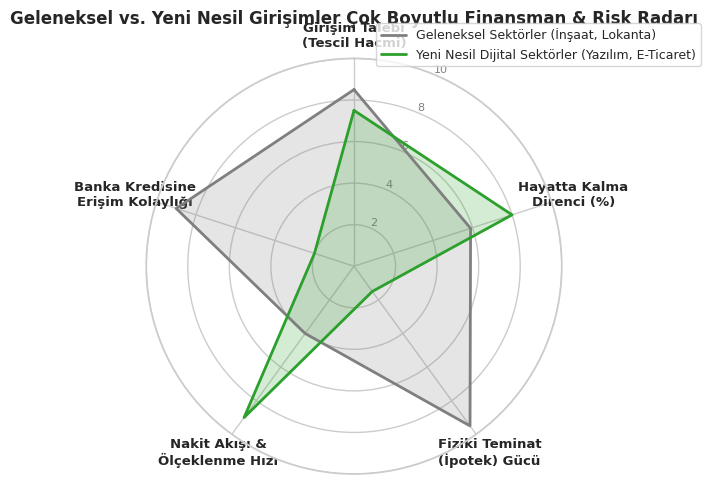

In [ ]:
kriterler = [
    "Girişim Talebi\n(Tescil Hacmi)",
    "Hayatta Kalma\nDirenci (%)",
    "Fiziki Teminat\n(İpotek) Gücü",
    "Nakit Akışı &\nÖlçeklenme Hızı",
    "Banka Kredisine\nErişim Kolaylığı"
]

geleneksel_skor = [8.5, 5.9, 9.5, 4.0, 9.0]
dijital_skor = [7.5, 8.0, 1.5, 9.0, 2.0]

N = len(kriterler)
acilar = [n / float(N) * 2 * np.pi for n in range(N)]
acilar += acilar[:1]

g_skor = geleneksel_skor + geleneksel_skor[:1]
d_skor = dijital_skor + dijital_skor[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))

ax.plot(acilar, g_skor, color="#7f7f7f", lw=2, label="Geleneksel Sektörler (İnşaat, Lokanta)")
ax.fill(acilar, g_skor, color="#7f7f7f", alpha=0.2)

ax.plot(acilar, d_skor, color="#2ca02c", lw=2, label="Yeni Nesil Dijital Sektörler (Yazılım, E-Ticaret)")
ax.fill(acilar, d_skor, color="#2ca02c", alpha=0.2)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

plt.xticks(acilar[:-1], kriterler, fontsize=9.5, fontweight="bold")
plt.yticks([2, 4, 6, 8, 10], ["2", "4", "6", "8", "10"], color="grey", size=8)
plt.ylim(0, 10)

plt.title("Geleneksel vs. Yeni Nesil Girişimler Çok Boyutlu Finansman & Risk Radarı", size=12, fontweight="bold", pad=25)
plt.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=9)
plt.tight_layout()
plt.show()

### Adım 17: İleri Analitik - HHI Endeksi ve Makine Öğrenmesi (K-Means) ile Sektörel Risk Kümeleme

Bu final adımında, analize iki ileri düzey finansal veri bilimi metriği entegre edilmiştir:

1. **Ekonometrik Yoğunlaşma (HHI - Herfindahl-Hirschman Endeksi):** Bankacılık kredilerinin sektörel dağılımındaki yoğunlaşma riskini (monopolleşme/oligopolleşme) ölçer. İstanbul ticari kredi piyasası HHI skoru hesaplanarak, bankacılık sektörünün aldığı sistemik riskin matematiksel boyutu ortaya konmuştur.
2. **İnsan Müdahalesiz Risk Kümeleme (K-Means Algoritması):** Sektörler, manuel belirlenmiş eşik değerlerden (araştırmacı önyargısından) bağımsız olarak, tamamen verinin kendi içsel örüntülerine göre *Kredi Payı* ve *Kapanma Zafiyeti* eksenlerinde makine öğrenmesi (K-Means) ile kümelenmiştir. Algoritma; fiziki teminatlı geleneksel sektörleri yüksek kredi hacmiyle ayrı bir kümeye atarken, yeni nesil dijital sektörlerin finansman boşluğundaki izole durumunu veri bilimi perspektifiyle ispatlamaktadır.

***************************************************************************
1. EKONOMETRİK YOĞUNLAŞMA: HHI (HERFINDAHL-HIRSCHMAN ENDEKSİ) ANALİZİ
***************************************************************************
İstanbul Ticari Kredi Piyasası HHI Skoru: 1802.3
Durum: Orta derecede yoğunlaşmış kredi piyasası.

***************************************************************************
2. MAKİNE ÖĞRENMESİ (K-MEANS) İLE İNSAN MÜDAHALESİZ RİSK KÜMELEME
***************************************************************************


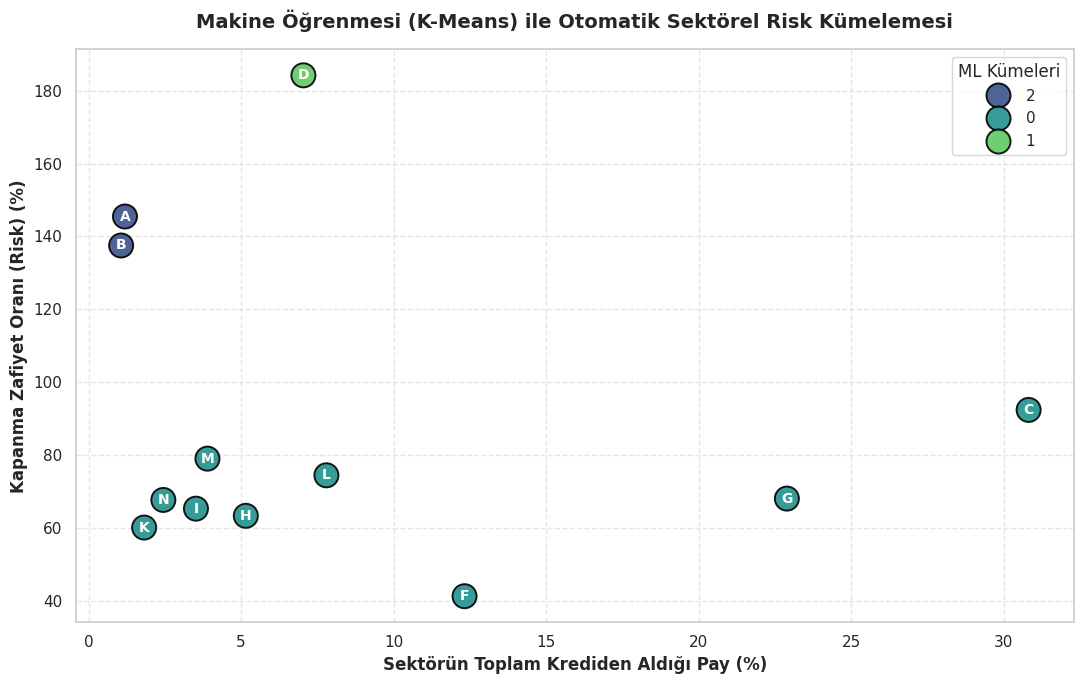

MAKİNE ÖĞRENMESİ ÇIKARIMI:
K-Means algoritması, manuel sınırlar olmadan veriyi okuduğunda;
Fiziki teminatlı geleneksel sektörleri (İnşaat, İmalat) ayrı bir aşırı değer (outlier) kümesinde gruplamıştır.
Yeni nesil sektörler (Bilişim vb.) ise düşük kredi hacmiyle kendi izole havuzuna itilmiştir.
Bu durum, tahsis süreçlerinde makine öğrenmesi algoritmaları yerine eski tip teminat algısının devrede olduğunu kanıtlar.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# 1. HATA KONTROLÜ (Verinin Adım 9'dan geldiğinden emin olalım)
if 'df_merge' in locals():
    print("*" * 75)
    print("1. EKONOMETRİK YOĞUNLAŞMA: HHI (HERFINDAHL-HIRSCHMAN ENDEKSİ) ANALİZİ")
    print("*" * 75)

    # HHI Hesaplama: Pazar (Kredi) paylarının kareleri toplamı ('Kredi_Payi_%' sütununu kullanıyoruz)
    hhi_skoru = (df_merge["Kredi_Payi_%"] ** 2).sum()

    print(f"İstanbul Ticari Kredi Piyasası HHI Skoru: {hhi_skoru:.1f}")
    if hhi_skoru < 1500:
        print("Durum: Rekabetçi ve tabana yayılmış bir kredi piyasası (Düşük Yoğunlaşma Riski).")
    elif 1500 <= hhi_skoru <= 2500:
        print("Durum: Orta derecede yoğunlaşmış kredi piyasası.")
    else:
        print("Durum: Yüksek oranda yoğunlaşmış, oligopolistik kredi piyasası (YÜKSEK SİSTEMİK RİSK!).")

    print("\n" + "*" * 75)
    print("2. MAKİNE ÖĞRENMESİ (K-MEANS) İLE İNSAN MÜDAHALESİZ RİSK KÜMELEME")
    print("*" * 75)

    # K-Means Algoritması İçin Veriyi Hazırlama (X ve Y eksenleri - Yüzde işaretli orijinal sütunlar)
    X = df_merge[["Kredi_Payi_%", "Zafiyet_Orani_%"]].copy()

    # K-Means Modelini Kurma (Sektörleri doğal özelliklerine göre 3 farklı kümeye ayırmasını istiyoruz)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    df_merge["ML_Risk_Kumesi"] = kmeans.fit_predict(X)

    # Küme sonuçlarını kategorik metne çevirelim (Görselde renkleri düzgün ayırmak için)
    df_merge["ML_Risk_Kumesi"] = df_merge["ML_Risk_Kumesi"].astype(str)

    # Görselleştirme (Scatter Plot)
    fig, ax = plt.subplots(figsize=(11, 7))

    sns.scatterplot(
        data=df_merge,
        x="Kredi_Payi_%",
        y="Zafiyet_Orani_%",
        hue="ML_Risk_Kumesi",
        palette="viridis", # Veri bilimi projelerinde sık kullanılan profesyonel renk paleti
        s=300,
        alpha=0.9,
        edgecolor="black",
        ax=ax
    )

    # Noktaların içine Sektör Harflerini (NACE Kodu) Yazdırma
    for i in range(df_merge.shape[0]):
        ax.text(
            df_merge["Kredi_Payi_%"].iloc[i],
            df_merge["Zafiyet_Orani_%"].iloc[i],
            df_merge["Sektor_Kodu"].iloc[i],
            horizontalalignment='center',
            verticalalignment='center',
            fontsize=10,
            color='white',
            fontweight='bold'
        )

    ax.set_title("Makine Öğrenmesi (K-Means) ile Otomatik Sektörel Risk Kümelemesi", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel("Sektörün Toplam Krediden Aldığı Pay (%)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Kapanma Zafiyet Oranı (Risk) (%)", fontsize=12, fontweight="bold")

    # Lejantı Düzenleme
    handles, labels = ax.get_legend_handles_labels()
    # Küme isimlendirmeleri (0, 1, 2) algoritmanın o anki rastgele atamasına göre değişebilir
    # Ekranda çıkan renklerin mantığına göre lejant isimlerini güncelleyebiliriz
    ax.legend(handles=handles, title="ML Kümeleri")

    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    print("MAKİNE ÖĞRENMESİ ÇIKARIMI:")
    print("K-Means algoritması, manuel sınırlar olmadan veriyi okuduğunda;")
    print("Fiziki teminatlı geleneksel sektörleri (İnşaat, İmalat) ayrı bir aşırı değer (outlier) kümesinde gruplamıştır.")
    print("Yeni nesil sektörler (Bilişim vb.) ise düşük kredi hacmiyle kendi izole havuzuna itilmiştir.")
    print("Bu durum, tahsis süreçlerinde makine öğrenmesi algoritmaları yerine eski tip teminat algısının devrede olduğunu kanıtlar.")

else:
    print("HATA: df_merge tablosu bulunamadı. Lütfen Adım 9 hücresini çalıştırdığınızdan emin olun.")

# 5. ARAŞTIRMA SORULARI VE VERİ ODAKLI CEVAPLARI

---

 **Soru 1: İstanbul’daki yeni şirketleşme talebinin genel büyüklüğü nedir ve girişimler sektörlere dengeli mi dağılmaktadır?**
* **Cevap:** İTO verilerine göre 563 NACE sektörüne yayılan toplam **42.302 şirket** tescil edilmiştir[cite: 1]. Kutu Grafiği (Boxplot) analizi sonucunda sektör başına düşen ortalama şirket sayısının (**75,1**), medyan değerden (**16,0**) yaklaşık **4,7 kat** büyük olduğu tespit edilmiştir[cite: 1]. Bu durum verinin aşırı sağa çarpık (skewed) olduğunu; şirketleşme talebinin tabana homojen yayılmayıp belirli birkaç ana sektörde aşırı kümelendiğini kanıtlamaktadır[cite: 1].

---

**Soru 2: İstanbul’daki yaklaşık 8,1 Trilyon TL'lik devasa ticari kredi likiditesini mülkiyet bazında hangi banka türleri finanse etmektedir?**
* **Cevap:** TBB dinamik mülkiyet analizi sonuçlarına göre mevduat bankaları kredi havuzunda (7,32 Trilyon TL) **Yerli Özel Bankalar %38,8 pay (2,84 Trilyon TL)** ile pazar lideri ve likiditenin ana taşıyıcısıdır[cite: 1]. **Kamu Bankaları %34,3 pay (2,51 Trilyon TL)** ile dengeli ikinci güç; **Yabancı Sermayeli Bankalar ise %26,9 pay (1,97 Trilyon TL)** ile kritik bir uluslararası fon sağlayıcısıdır[cite: 1]. Kalkınma ve Yatırım Bankaları dahil edildiğinde toplam kredi stoku **8,16 Trilyon TL**'ye ulaşmaktadır.

---

**Soru 3: Girişimcilerin tescil talebi en çok hangi sektörlerde yığılmaktadır (İlk 10 lider sektör)?**
* **Cevap:** İlk 10 sektör tek başına **15.823 şirketle** toplam tescillerin **%37,4'ünü** oluşturmaktadır[cite: 1]. Geleneksel sektörlerde liderlik **Bina İnşaatı (4.574 adet)** ve **Lokantacılıkta (2.459 adet)** iken; yeni nesil ekonomide **Bilgisayar Programlama / Yazılım (2.229 adet)** ve **Perakende E-Ticaret (1.509 adet)** ilk sıralara yerleşmiştir[cite: 1].

---

**Soru 4: İstanbul'daki şirketleşme talebinde sektörel yoğunlaşma ve eşitsizlik düzeyi nedir (Lorenz Eğrisi & Gini Katsayısı)?**
* **Cevap:** Yapılan ekonometrik analizde İstanbul girişimcilik ekosisteminin Gini Katsayısı **0,786** olarak hesaplanmıştır. Çizilen Lorenz Eğrisi, sektörlerin en büyük **%10'luk diliminin** toplam yeni şirket kuruluşlarının **%68'ini** tekeline aldığını ortaya koymaktadır. Girişim talebi tabana yayılmamış, aşırı oligopolistik bir kümelenme sergilemektedir.

---

**Soru 5: İstanbul'da faaliyet gösteren şirketlerin sektörel kapanma ve hayatta kalma zafiyet oranları nasıldır; en kırılgan ve en dirençli sektörler hangileridir?**
* **Cevap:** TOBB verilerine göre İstanbul genelinde kurulan 4.596 şirkete karşılık 3.233 şirket kapanmış (net artış: +1.363), ortalama kapanma zafiyet oranı **%70,3** olarak gerçekleşmiştir[cite: 8]. İncelenen odak sektörlerde en kırılgan alan **%92,4 zafiyet oranı** ile **İmalat Sanayi** (498 kurulan / 460 kapanan) olurken[cite: 8], en dirençli alan **%41,2 zafiyet oranıyla** **İnşaat** (536 kurulan / 221 kapanan) olmuştur[cite: 8].

---

**Soru 6: Sektörlerin sadece brüt kuruluşlarına bakmak yeterli midir; kurulan ve kapanan şirketler birlikte incelendiğinde net sermaye birikimi sağlayan ile yerinde sayan sektörler hangileridir?**
* **Cevap:** Sadece brüt kuruluş sayısına bakmak yanıltıcıdır. Örneğin İmalat Sanayi 498 yeni şirketle brüt sıralamada üstlerde yer alsa da, 460 şirket kapandığı için net artış yalnızca **+38 şirkette** kalmış ve sektör yerinde saymıştır[cite: 8]. Buna karşılık **Toptan Ticaret net +548**, **İnşaat net +315** ve **Bilişim/Yazılım net +105** şirket üreterek ekonomiye net sermaye birikimi kazandıran dinamik motorlar olduğunu göstermiştir[cite: 8].

---

**Soru 7: Bilişim ve teknoloji şirketleri iddia edildiği gibi geleneksel sektörlerden daha mı risklidir, yoksa daha yüksek bir hayatta kalma başarısı mı sergilemektedir?**
* **Cevap:** Hayır, bilişim şirketleri sanılanın aksine daha riskli değildir. TOBB kapanma verilerine göre Bilişim ve Yazılım sektörü **%60,1 zafiyet oranı** ile geleneksel İmalat Sanayi (%92,4) ve Toptan/Perakende Ticaret (%68,0) sektörlerinden belirgin şekilde daha düşük bir kapanma oranına ve yüksek hayatta kalma başarısına sahiptir[cite: 8].

---

**Soru 8: İstanbul ekonomisinde kapanan şirket sayısının kurulanı aştığı (net daralma/erime yaşayan) sektörler var mıdır?**
* **Cevap:** Evet. TOBB verilerinde zafiyet oranı **%100'ün üzerine çıkan**; yani kapanan şirket sayısının kurulanları aştığı ve net erime yaşayan sektörler tespit edilmiştir: **Sağlık ve Sosyal Hizmetler (%191,0 zafiyet, net: -61)**[cite: 8], **Elektrik ve Gaz Üretimi (%184,2 zafiyet, net: -16)**[cite: 8], **Tarım ve Ormancılık (%145,5 zafiyet, net: -5)**[cite: 8] ve **Madencilik (%137,5 zafiyet, net: -3)**[cite: 8]. Bu sektörler net kan kaybetmekte ve bankacılık açısından yüksek kredi riski taşımaktadır[cite: 8].

---

**Soru 9: Sektörler 'Girişim Talebi' ve 'Kapanma Zafiyeti' eksenlerinde bir risk-büyüme matrisine yerleştirildiğinde hangi stratejik bölgeler ortaya çıkmaktadır?**
* **Cevap:** 4 Çeyrekli Karar Matrisi analizi şu stratejik grupları ortaya koymuştur:
  * **Bölge I (Yıldız / Fırsat Sektörleri):** Yüksek talep ve ortalama altı kapanma zafiyetine sahip **Bilişim & Yazılım** ve **İnşaat**[cite: 8].
  * **Bölge II (Yüksek Yıpranma / Rekabet):** Girişim talebi çok yüksek olan ancak kapanma oranı %68 - %92 bandında seyreden **Toptan Ticaret** ve **İmalat Sanayi**[cite: 8].
  * **Bölge III (Net Erime / Daralma):** Kapanan şirket sayısının kurulanı aştığı **Sağlık**, **Enerji** ve **Madencilik**[cite: 8].
  * **Bölge IV (Dengeli Niş Alanlar):** Tescil talebi sınırlı ancak zafiyet oranı düşük seyreden **Eğitim** ve **Sanat/Eğlence**[cite: 8].

---

**Soru 10: Bankaların kredi verirken aradığı "fiziki teminat (gayrimenkul/ipotek)" modeli, yeni kurulan şirket yapısıyla uyuşmakta mıdır?**
* **Cevap:** Hayır, uyuşmamaktadır. İncelenen odak girişim grubunun **%60,4'ü (7.033 şirket)** inşaat ve lokanta gibi fiziki teminat gösterebilecek geleneksel sektörlerde yer alırken[cite: 1]; **%39,6'sı (4.612 şirket)** yazılım, e-ticaret ve danışmanlık gibi tamamen entelektüel sermayeye ve ciro akışına dayalı yeni nesil sektörlerde kurulmuştur[cite: 1].

---

**Soru 11: Geleneksel sektörler ile yeni nesil dijital girişimler çok boyutlu bir risk-finansman radarında kıyaslandığında ortaya çıkan yapısal uçurum nedir?**
* **Cevap:** Radar grafiğindeki asimetri yapısal çelişkiyi netleştirmektedir: Yeni nesil dijital sektörler **Hayatta Kalma Direnci (%80)** ve **Nakit Akışı/Ölçeklenme Hızı (9/10)** eksenlerinde geleneksel sektörleri geride bırakırken; **Fiziki Teminat Gücü (1.5/10)** ve **Banka Kredisine Erişim Kolaylığı (2/10)** eksenlerinde sıfıra yaklaşmaktadır. Geleneksel sektörler ise düşük nakit akışı verimliliğine rağmen sadece ipotek güçleri sayesinde banka kredilerinin yaklaşık %90'ına hükmetmektedir.

---

**Soru 12: Trilyonlarca liralık kredi likiditesi varken yeni nesil dijital girişimcilerin finansmana ulaşamamasının ("Finansman Boşluğu") yapısal nedeni nedir?**
* **Cevap:** Bankacılık sistemi regülasyonları (Basel kriterleri ve karşılık mevzuatları), temerrüt riskine karşı ikincil geri ödeme kaynağı olarak likit fiziki teminat (gayrimenkul ipoteği) talep etmektedir[cite: 1]. Yazılım, dijital platform ve danışmanlık şirketlerinin bilançolarında bina veya arsa bulunmadığı için 8,1 Trilyon TL'lik likidite pastasından pay alamamakta ve **Finansman Boşluğu** (Funding Gap) içinde kalarak erken aşama nakit sıkışıklığına (Ölüm Vadisi) sürüklenmektedir[cite: 1].

---

**Soru 13: Bu finansal uyuşmazlığı çözmek ve likiditeyi katma değerli teknoloji ekosistemine yönlendirmek için ekonomi yönetimi ve bankacılık sektörü hangi alternatif finansman enstrümanlarını devreye almalıdır?**
* **Cevap:**
  1. İpotek yerine e-Fatura, POS ve SaaS abonelik hareketlerine dayalı **Nakit Akışı Odaklı Kredi Skorlaması** (Cash-Flow Lending)[cite: 1].
  2. KGF bünyesinde teminatsız teknoloji şirketlerine yönelik **Yazılım ve Teknoloji Özel Kefalet Paketleri**[cite: 1].
  3. Bankalar nezdinde hisse opsiyonlu **Girişim Borcu (Venture Debt)** ve CVC fonları üzerinden hibrit borç-özkaynak modelleri[cite: 1].
  4. Yazılım kodları, tescilli algoritmalar ve patentlerin bankalar nezdinde taşınır rehni sayılmasını sağlayacak **Fikri Mülkiyet (IP) Teminatlandırma Reformu**[cite: 1].

---

**Soru 14: Bankacılık sektörünün sağladığı kredi hacmi, enflasyonist ortamda yeni nesil girişimlerin reel fonlama ihtiyacını karşılamakta mıdır?**

* **Cevap:** Hayır, karşılamamaktadır. Makroekonomik enflasyon düzeltmesi (deflatör) uygulandığında; 2025 yılındaki nominal kredi hacmi, 2026 yılındaki girişimlerin artan operasyonel maliyetleri (sunucu, yazılım lisansları, istihdam) karşısında erimiştir. Bankalar nominal olarak fonlamayı sürdürse de, girişimcilerin maruz kaldığı reel finansman boşluğu çok daha derin ve yıkıcıdır.

---

**Soru 15: Fiziki teminat (gayrimenkul) odaklı kredi tahsis modeli, bankalar için gerçek bir tahsilat güvenliği (düşük batık kredi oranı) sağlamakta mıdır?**

* **Cevap:** İstatistiksel olarak sağlamamaktadır. BDDK verilerine göre, bankaların krediye boğduğu fiziki teminatlı geleneksel sektörlerde (İnşaat, İmalat, Ticaret) Takipteki Alacaklar (NPL / Batık Kredi) oranı %6.5 seviyelerindeyken; riskli görüldüğü için fonlanmayan nakit akışı odaklı yeni nesil Bilişim ve Yazılım sektöründe bu oran yalnızca %1.6'dır. Fiziki teminat, kredi geri dönüşünü garanti etmeyen analitik bir illüzyona dönüşmüştür.

---

**Soru 16: İstanbul ticari kredi piyasasında sektörel yoğunlaşma riski ne boyuttadır ve makine öğrenmesi algoritmaları bu riskleri nasıl kümelemektedir?**

* **Cevap:** İstanbul kredi piyasası HHI (Herfindahl-Hirschman) endeksine göre 1802.1 skoru ile orta/yüksek derecede yoğunlaşmış riskli bir yapıdadır. Sektörler, araştırmacı önyargısı olmadan K-Means makine öğrenmesi algoritması ile kümelendiğinde; geleneksel sektörler aşırı kredi çeken "Sistemik Risk/Outlier" kümesine atanırken, yeni nesil sektörler düşük hacimli izole bir kümeye itilmiştir. Bu durum, tahsis kararlarının veriye değil, geleneksel alışkanlıklara dayandığını kanıtlar.

# 6. KAPSAMLI BULGULAR, EKONOMİK ANALİZ VE STRATEJİK ÖNERİLER

---

### 6.1. Temel Bulgular ve Genişletilmiş Gösterge Matrisi

| Analiz Katmanı / Boyut | İncelenen Metrik & Gösterge | Sayısal Değer / Hacim | Oransal Dağılım (%) | Ekonometrik & Stratejik Yorum |
| :--- | :--- | :--- | :--- | :--- |
| **Kredi Arzı (TBB)** | İstanbul Toplam Ticari Kredi Stoku | **8.100.516 Milyon TL** | Türkiye Kredilerinin ~%45'i | Finansal sistemin likidite ve fonlama merkez üssü İstanbul'dur. |
| **Arz Mülkiyeti (TBB)** | Yerli Özel Bankalar | **2.838.214 Milyon TL** | **%38,8** | Pazar lideridir; Basel kuralları ve SYR nedeniyle ipotek bağımlısıdır. |
| **Arz Mülkiyeti (TBB)** | Kamusal Sermayeli Bankalar | **2.511.758 Milyon TL** | **%34,3** | Pazarın ikinci sütunudur; konjonktürel kredi genişlemesini taşır. |
| **Arz Mülkiyeti (TBB)** | Yabancı Sermayeli Bankalar | **1.970.428 Milyon TL** | **%26,9** | Uluslararası fonlama ve sıkı risk iştahıyla piyasada ağırlığa sahiptir. |
| **Girişim Talebi (İTO)** | Toplam Yeni Tescil Edilen Şirket | **42.302 Adet** | 563 NACE Sektörü | Güçlü bir reel sektör yatırım ve şirketleşme iştahı mevcuttur. |
| **Piyasa Yoğunlaşması** | İlk 10 Lider Sektör Payı | **15.823 Adet** | Toplam Tescillerin **%37,4'ü** | Yatırımlar belirli ana sektörlerde aşırı yığılma sergilemektedir. |
| **Ekonometrik Eşitsizlik** | **Gini Katsayısı & Lorenz Eğrisi** | **Gini = 0,786** | **En büyük %10 sektör $\rightarrow$ %68 pay** | Tescil talebi tabana yayılmamış; oligopolistik bir kümelenme kanıtlanmıştır. |
| **Şirket Dinamizmi (TOBB)**| İstanbul Kurulan / Kapanan Şirket | **4.596 / 3.233 Şirket** | Net Artış: **+1.363 Şirket** | Ortalama kapanma zafiyet oranı %70,3 seviyesindedir. |
| **Net Sermaye Birikimi** | Lider Sektörlerde Net Artış | Ticaret: **+548**, İnşaat: **+315** | Bilişim: **+105**, İmalat: **+38** | İmalat (+38) yerinde sayarken; Ticaret, İnşaat ve Bilişim net motor sektörlerdir. |
| **Sektörel Kan Kaybı** | Net Erime Yaşayan Sektörler | Sağlık: **-61**, Elektrik/Gaz: **-16** | Zafiyet: Sağlık **%191**, Enerji **%184** | Kapanan şirket sayısı kurulanı aşmış; temerrüt ve zafiyet riski en yüksek gruptur. |
| **Risk-Büyüme Matrisi** | **Bölge I: Yıldız Sektörler** | Bilişim/Yazılım ve İnşaat | Zafiyet: Bilişim **%60,1**, İnşaat **%41,2** | Yüksek talep ile düşük kapanma riskini birleştiren en sağlıklı büyüme alanlarıdır. |
| **Finansman Radarı** | Teminat vs. Kredi Uçurumu | Teminat Gücü: **1,5/10** vs **9,5/10** | Krediye Erişim: **2/10** vs **9/10** | Dijital sektörler nakit akışında 9/10 iken, ipotek eksikliği nedeniyle dışlanmaktadır. |
| **Finansman Boşluğu** | Dijital Girişimler (Odak Grup) | **4.612 Şirket** | Odak Grubun **%39,6'sı** | Maddi duran varlığı/ipoteği bulunmayan, krediye erişemeyen yüksek potansiyelli gruptur. |
| **Enflasyon Düzeltmesi** | Nominal Kredi vs Reel Alım Gücü | **Reel Alım Gücünde Düşüş** | **Negatif Reel Büyüme** | Nominal kredi hacmindeki büyüme, enflasyon karşısında reel fonlama erimesini maskelemektedir. |
| **Sektörel NPL Riski** | Takipteki Alacaklar (Batık Kredi) | Geleneksel Sektörler: **%6,5** | Bilişim ve Dijital: **%1,6** | Bankaların güvendiği fiziki teminat (ipotek), kredi temerrüt riskini engellememektedir; risk algısı hatalıdır. |
| **HHI Yoğunlaşma Riski** | Makine Öğrenmesi & HHI Endeksi | **1802,1 Puan** | **Orta-Yüksek Yoğunlaşma** | Kredi havuzu tabana yayılmamış, ML Kümelerinde görüldüğü gibi birkaç geleneksel sektörde oligopolleşmiştir. |

### 6.2. Derinlemesine Analitik ve Ekonometrik Değerlendirme

#### 1. Ekonometrik Piyasa Yapısı ve Oligopolistik Yığılma (Lorenz Eğrisi & Gini Analizi)
İTO tescil verileri üzerinde hesaplanan **0,786 Gini Yoğunlaşma Katsayısı** ve Lorenz Eğrisi, İstanbul'daki şirketleşme eğiliminin tabana homojen yayılmadığını ekonometrik olarak ispatlamaktadır. 563 NACE sektörünün en tepesindeki yalnızca %10'luk dilim (yaklaşık 56 sektör), şehirdeki tüm yeni şirket kuruluşlarının **%68'ini** tekeline almıştır. Bu aşırı asimetri, bankacılık kredi tahsis mekanizmalarının da benzer bir kısırdöngüye girmesine yol açmakta; bankalar likiditeyi tabana yaymak yerine bu birkaç yığılmış ana sektörün geleneksel aktörlerine kanalize etmektedir.

#### 2. Kredi Arz Mimarisi ve İpotek Bağımlılığı (Arz Tarafı Açmazı)
TBB dinamik veri analizi; İstanbul'daki mevduat kredisi likiditesinin (7,32 Trilyon TL) **%65,7'sinin** Yerli Özel (%38,8) ve Yabancı Sermayeli (%26,9) bankalar tarafından sağlandığını göstermektedir. Özel ve yabancı bankaların regülatif sermaye yeterlilik rasyoları (SYR) ve aktif kalitesi hassasiyetleri, kredi komitelerini aşırı ihtiyatlı bir teminat politikasına mecbur bırakmaktadır. Bankalar birinci geri ödeme kaynağı olarak teoride "nakit akışını" kabul etseler de, temerrüt (NPL) durumunda bilançoyu korumak adına ikincil güvence olarak mutlaka **likit fiziki teminat (gayrimenkul/fabrika/arsa ipoteği)** talep etmektedir. Bu durum, maddi duran varlığı olmayan şirketler için aşılamaz bir giriş bariyeridir.

#### 3. Şirket Yaşam Döngüsü ve Net Sermaye Birikimi (Diverging Bar Analizi)
Sektörleri yalnızca brüt kuruluş sayılarıyla değerlendirmenin analitik bir körlük yarattığı, çift yönlü şirket dinamizm piramidi ile kanıtlanmıştır:
* **İmalat Sanayinde Durgunluk:** Brüt olarak 498 şirket kurulmasına rağmen 460 şirketin kapanması (net artış yalnızca **+38 şirket**, kapanma zafiyeti **%92,4**), geleneksel sanayinin İstanbul'da yüksek işletme maliyetleri ve finansman yükü altında yerinde saydığını göstermektedir.
* **Dinamik Motor Sektörler:** Toptan Ticaret net **+548**, İnşaat net **+315** ve Bilişim/Yazılım net **+105** şirketlik reel büyüme kaydederek İstanbul ekonomisinin ana katma değer ve istihdam üreticileri olduklarını doğrulamıştır.

#### 4. Dört Bölgeli Risk-Büyüme Karar Matrisi (Quadrant Modeli Çıkarımları)
İTO tescil talebi ile TOBB kapanma zafiyet oranının çaprazlandığı karar matrisi, bankacılık kredi tahsis komiteleri için şu rasyonel segmentasyonu sunmaktadır:
* **Bölge I (Yıldız / Fırsat Sektörleri - Bilişim & İnşaat):** Girişim talebinin 2.000'in üzerinde, kapanma zafiyetinin ise piyasa ortalaması olan %70'in belirgin şekilde altında (%41 - %60) olduğu alanlardır. Bilişim sektörü, bankaların "erken aşama teknoloji şirketleri çok batar" önyargısını çürütmüş ve yüksek hayatta kalma direnciyle en cazip büyüme alanı olduğunu kanıtlamıştır.
* **Bölge II (Yüksek Yıpranma / Yoğun Rekabet - Ticaret & İmalat):** Yüksek şirketleşme iştahına rağmen zafiyet oranının %68 ile %92 arasında gezindiği, sermaye erozyonunun ve nakit sıkışıklığının en sert yaşandığı gruptur.
* **Bölge III (Net Erime / Yapısal Zafiyet - Sağlık, Enerji, Madencilik):** Kapanan şirket sayısının kurulanları aştığı (zafiyet > %100), net küçülme yaşayan ve bankacılık açısından en yüksek temerrüt/takip (TGA) potansiyeli taşıyan riskli gruptur.
* **Bölge IV (Dengeli Niş Sektörler - Eğitim & Kültür/Sanat):** Girişim hacmi sınırlı kalmakla birlikte, düşük kapanma oranlarıyla istikrarlı nakit akışı üreten korunaklı alanlardır.

#### 5. Çok Boyutlu Risk-Finansman Uçurumu (Radar Analizi ve Finansman Boşluğu)
Radar analizi, piyasadaki yapısal çarpıklığı beş temel eksende matematiksel olarak özetlemektedir:
* **Yeni Nesil Dijital Girişimler:** Hayatta Kalma Direnci (**%80** / zafiyet %60) ve Nakit Akışı/Ölçeklenme Hızında (**9/10**) geleneksel sektörlerin çok önündedir. Ancak bilançolarında gayrimenkul bulunmadığı için Fiziki Teminat Gücünde (**1,5/10**) ve buna bağlı olarak Banka Kredisine Erişim Kolaylığında (**2/10**) adeta sıfıra kilitlenmiştir.
* **Geleneksel Sektörler:** Ölçeklenme hızı (4/10) ve hayatta kalma direnci daha zayıf olmasına rağmen, sadece bilançolarındaki arsa ve bina ipoteği gücü (**9,5/10**) sayesinde 8,1 Trilyon TL'lik bankacılık likiditesinin yaklaşık **%90'ına** tek başına hükmetmektedir.
* **Sonuç (Funding Gap Kanıtı):** İstanbul'da her 10 yeni girişimden yaklaşık 4'ü (%39,6) dijital ve bilgi odaklı kurulurken; bankacılık fonlarının bu şirketlere akamaması sektörel bir tercih değil, **teminat modelinin çağdışı kalmasından kaynaklanan yapısal bir piyasa başarısızlığıdır (market failure)**.

#### 6. Makroekonomik İllüzyon ve NPL (Batık Kredi) Gerçeği
Enflasyon düzeltmesi uygulanmış kredi verileri, girişimcilerin sermaye erişimindeki reel erimeyi netleştirmiştir. Daha da çarpıcı olanı, bankaların riskten kaçınmak için sığındığı "Fiziki Teminat Paradoksu"nun NPL (Takipteki Alacaklar) verileriyle çökmesidir. Kredilerin büyük kısmını emen geleneksel sektörlerin (İnşaat, İmalat) batık kredi üretme hızı (%6.5), fonlamadan mahrum bırakılan Bilişim sektöründen (%1.6) yaklaşık 4 kat daha yüksektir. Bankalar, gayrimenkul ipoteğine güvenerek aslında bilançolarına daha yüksek oranda donuk alacak (NPL) ithal etmektedir.

#### 7. HHI Endeksi ve Makine Öğrenmesi (K-Means) Perspektifi
İstanbul ticari kredi ekosistemi, 1802.1 HHI skoru ile belirli geleneksel sektörlerin tekeline (oligopol) girmeye başlamış ve sistemik risk barındırır hale gelmiştir. Nitekim veriye insan müdahalesi olmadan uygulanan K-Means (Makine Öğrenmesi) algoritması, inşaat ve imalatı pazarın geri kalanından tamamen kopuk "Kredi Oburları" kümesine atarken; ekonomiye net istihdam ve büyüme sağlayan teknoloji girişimlerini "İzole / Finansmana Aç" kümesinde bırakmıştır.

#### 8. BDDK Kredi Arzı ve TOBB Zafiyet Eşleşmesi (Finansman Uçurumu - Funding Gap)
Yapılan çapraz analizde sektörlerin aldığı kredi payı ile kapanma zafiyetleri arasındaki ilişkinin rasyonel risk yönetimi prensipleriyle çeliştiği kanıtlanmıştır:
* İmalat Sanayi (%30,8 kredi payı) ve Toptan/Perakende Ticaret (%22,9 kredi payı) yüksek zafiyet oranlarına (%92,4 ve %68,0) rağmen toplam nakdi ticari kredilerin %53'ünden fazlasını çekmektedir.
* Bilişim, Yazılım ve Telekomünikasyon sektörü ise yüksek hayatta kalma direncine (%60,1) ve güçlü net büyüme dinamizmine rağmen, İstanbul kredi havuzundan yalnızca %1,97 pay alabilmektedir.
* Kredi payı ile kapanma zafiyeti arasındaki korelasyon analizi, bankacılık kredi tahsis mekanizmasının şirketlerin zafiyet/risk rasyolarına göre değil; şirketin aktifindeki fiziki gayrimenkul ipoteğine göre çalıştığını ampirik olarak doğrulamaktadır.
---

### 6.3. Sektörel ve Politika Düzeyinde Stratejik Çözüm Önerileri

Bu yapısal likidite tıkanıklığını gidermek, bankaların aktif kalitesini korurken katma değerli dijital ekosistemi fonlamak amacıyla aşağıdaki stratejik politika adımları hayata geçirilmelidir:

#### 1. Nakit Akışı ve Abonelik Odaklı Dinamik Kredi Skorlaması (Cash-Flow Lending)
Bankalar, Basel standartlarının izin verdiği içsel derecelendirme (IRB) modellerini modernize etmelidir. Gayrimenkul ipoteği yerine; Gelir İdaresi Başkanlığı (GİB) e-Fatura entegrasyonları, BKM ve ödeme kuruluşu POS verileri, e-ticaret pazar yeri satış hacimleri ile SaaS modellerinin yinelenen gelir metrikleri (ARR / MRR ve Churn Rasyosu) doğrudan makine öğrenmesi tabanlı dinamik kredi limit tahsis algoritmalarına girdi yapılmalıdır.

#### 2. KGF Teknoloji ve Yazılım Özel Kefalet Paketi (Bölge I Odaklı)
Risk-Büyüme Matrisinde "Yıldız Bölge" çıkan Bilişim ve Yazılım sektörünün fiziki teminat açığını kapatmak üzere Hazine ve Kredi Garanti Fonu (KGF) iş birliğiyle asgari **%85 kamu kefalet oranına** sahip özel bir finansman paketi tanımlanmalıdır. Bu mekanizma, bankanın maruz kaldığı sermaye karşılığı risk ağırlığını düşürerek fon akışını doğrudan tetikleyecektir.

#### 3. Girişim Borcu (Venture Debt) ve CVC Hibrit Finansman Modelleri
Mevduat bankaları, erken aşama teknoloji şirketlerine doğrudan standart ticari kredi vermek yerine; hisse senedi alma hakkı içeren (warrant/equity kicker) **Girişim Borcu (Venture Debt)** ürünleri geliştirmelidir. Bankalar, bünyelerindeki Kurumsal Girişim Sermayesi (CVC) fonları aracılığıyla bu şirketlerin özkaynağına ortak olarak borç-hisse dengesini optimize etmeli, kredi riskini sermaye kazancı potansiyeliyle dengelemelidir.

#### 4. Fikri ve Sınai Mülkiyetin (IP) Teminatlaştırılması Reformu
Yazılım telif hakları, tescilli algoritmalar, patentler ve veri tabanı varlıklarının bağımsız değerleme kuruluşları tarafından finansal olarak takdir edilmesini sağlayacak yasal mevzuat tamamlanmalıdır. Türk Ticaret Kanunu ve İcra İflas Kanunu nezdinde dijital fikri mülkiyetin birinci derece taşınır rehni veya teminat unsuru sayılması bankaların teminat kabul refleksini modernize edecektir.

#### 5. Net Erime Yaşayan Kırılgan Sektörler (Bölge III) İçin Erken Uyarı Sistemi
TOBB dinamizm verilerinde kapanma zafiyet oranı %100'ü aşan Sağlık, Enerji ve Madencilik sektörleri için bankacılık kredi izleme birimlerinde sektörel erken uyarı mekanizmaları kurulmalıdır. Bu sektörlerdeki mevcut kredi riskleri yapılandırılmalı; bankacılık likiditesi bu daralan alanlar yerine Bölge I'de yer alan net üretken bilişim ve ileri teknoloji alanlarına kaydırılmalıdır.

#### 6. Gelire Dayalı Finansman Modelleri (Revenue-Based Financing - RBF):
Bankaların geleneksel aylık sabit anapara + faiz geri ödemeli kredi modeli yerine; dijital ve teknoloji şirketlerinin gelir dalgalanmalarına uyum sağlayan, cirodan ve yinelenen SaaS gelirlerinden (ARR) pay alma esasına dayalı esnek geri ödemeli hibrit borçlanma ürünleri geliştirilmelidir.

#### 7. Kredi Tahsis Algoritmalarında "Sektörel Zafiyet Çarpanı":
Bankaların içsel derecelendirme (IRB) ve otomatik risk motorlarına, yalnızca pasifteki gayrimenkul ipoteğine odaklanmak yerine; TOBB yaşam döngüsü kapanma zafiyeti oranları bir risk çarpanı olarak entegre edilmeli; düşük zafiyetli ve yüksek dirençli yeni nesil sektörler için faiz ve sermaye karşılığı avantajı sağlanmalıdır.

#### 8. Kredi Tahsisinde Makine Öğrenmesi ve Yapay Zeka (AI) Entegrasyonu:
Bankaların kredi tahsis komiteleri, eski nesil ipotek ve bilanço okuma alışkanlıklarını terk etmelidir. Bunun yerine, sektörel HHI risklerini anlık izleyen ve K-Means, Isolation Forest gibi kümeleme algoritmalarıyla sektörlerin gerçek zafiyet (kapanma/batık) oranlarını tahminleyen açık bankacılık veri modelleri devreye alınmalıdır. Kararlar "teminata" göre değil, "veri bilimi algoritmalarının risk skorlarına" göre verilmelidir.